<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Contexte-de-l'étude" data-toc-modified-id="Contexte-de-l'étude-1">Contexte de l'étude</a></span></li><li><span><a href="#Préparation-des-bases-de-données" data-toc-modified-id="Préparation-des-bases-de-données-2">Préparation des bases de données</a></span><ul class="toc-item"><li><span><a href="#Importation-des-librairies-et-fonctions-personnalisées" data-toc-modified-id="Importation-des-librairies-et-fonctions-personnalisées-2.1">Importation des librairies et fonctions personnalisées</a></span></li><li><span><a href="#Importation-des-jeux-de-données" data-toc-modified-id="Importation-des-jeux-de-données-2.2">Importation des jeux de données</a></span></li><li><span><a href="#Récapitulatif-des-bases-de-données" data-toc-modified-id="Récapitulatif-des-bases-de-données-2.3">Récapitulatif des bases de données</a></span></li></ul></li><li><span><a href="#Analyses-descriptives" data-toc-modified-id="Analyses-descriptives-3">Analyses descriptives</a></span><ul class="toc-item"><li><span><a href="#Correlation-de-Pearson" data-toc-modified-id="Correlation-de-Pearson-3.1">Correlation de Pearson</a></span></li><li><span><a href="#Analyse-en-composantes-principales-(ACP)" data-toc-modified-id="Analyse-en-composantes-principales-(ACP)-3.2">Analyse en composantes principales (ACP)</a></span></li><li><span><a href="#Partitionner-avec-l'algorithme--k-means" data-toc-modified-id="Partitionner-avec-l'algorithme--k-means-3.3">Partitionner avec l'algorithme  k-means</a></span></li></ul></li><li><span><a href="#Analyses-explicatives" data-toc-modified-id="Analyses-explicatives-4">Analyses explicatives</a></span><ul class="toc-item"><li><span><a href="#une-variable-quantitative-et-une-variable-qualitative-:-ANOVA" data-toc-modified-id="une-variable-quantitative-et-une-variable-qualitative-:-ANOVA-4.1">une variable quantitative et une variable qualitative : ANOVA</a></span></li><li><span><a href="#Deux-variables-qualitatives-:-CHI-2" data-toc-modified-id="Deux-variables-qualitatives-:-CHI-2-4.2">Deux variables qualitatives : CHI-2</a></span></li></ul></li><li><span><a href="#Conclusion" data-toc-modified-id="Conclusion-5">Conclusion</a></span></li></ul></div>

# Contexte de l'étude

Ce notebook présente la réalisation d'une première exploration et analyse des données. 

L'analyse est basée sur le jeu de données Open Food Facts.

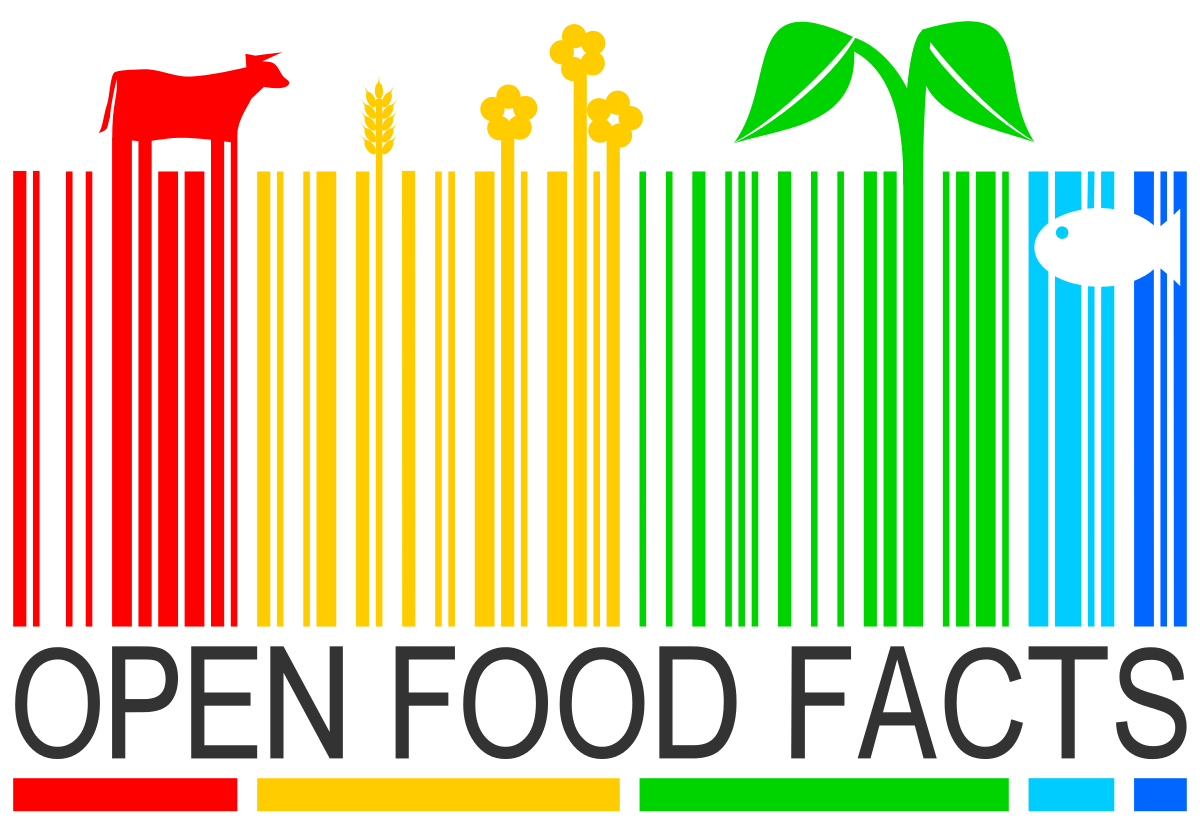

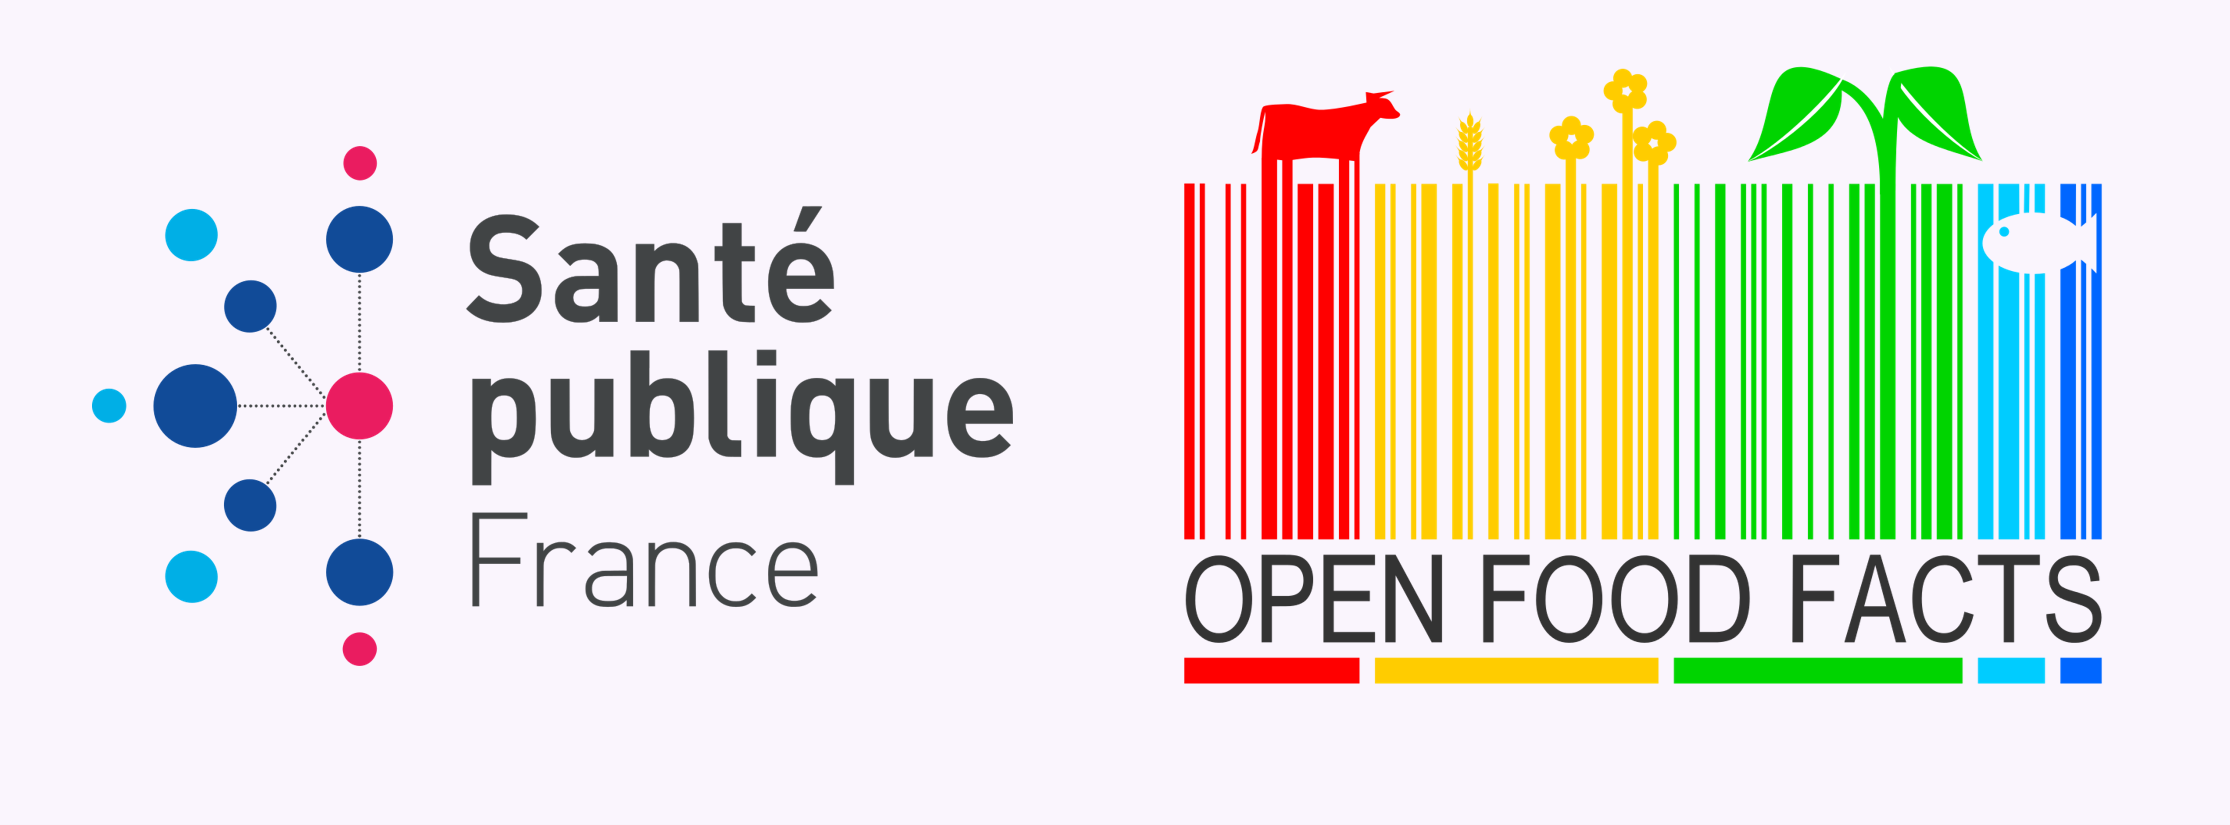

# Préparation des bases de données

## Importation des librairies et fonctions personnalisées

Les librairies nécessaires pour l'étude sont importées dans l'environnement de travail.

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import datetime  # Manipuler dates et heures

In [2]:
from my_functions import *

## Importation des jeux de données

In [3]:
chemin = "C:/Users/smora/Desktop/Les projets OC/Projet 03/Données"

In [4]:
df_net = pd.read_csv(chemin + "/export_df_net.csv", sep='\t', low_memory=False)
compte_additifs = pd.read_csv(chemin + "/export_compte_additifs.csv",
                              sep='\t',
                              low_memory=False)
compte_ingredients = pd.read_csv(chemin + "/export_compte_ingredients.csv",
                                 sep='\t',
                                 low_memory=False)
data_pnns = pd.read_csv(chemin + "/export_data_pnns.csv",
                        sep='\t',
                        low_memory=False)
data_packaging = pd.read_csv(chemin + "/export_data_packaging.csv",
                             sep='\t',
                             low_memory=False)
data_matiere = pd.read_csv(chemin + "/export_data_matiere.csv",
                           sep='\t',
                           low_memory=False)

## Récapitulatif des bases de données

In [5]:
df_net.head()  #Base de données principale

,code,created_t,product_name,brands_tags,labels_tags,serving_quantity,additives_n,ingredients_from_palm_oil_n,ingredients_that_may_be_from_palm_oil_n,nutriscore_score,...,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,countries,solide_ou_liquide,year,boisson_ou_aliment,score_fruits_vegetables
0,0000000000017,1529059080,Vitória crackers,unknown,Unknown,2.040371e+08,2,0,0,14.0,...,0.560,0.012460,0.077388,0.144409,0.015516,France,Unknown,2018,aliment,0
1,000000000003327986,1574175736,Filetes de pollo empanado,unknown,Unknown,2.040371e+08,2,0,0,9.0,...,0.440,0.012460,0.077388,0.144409,0.015516,Espagne,Unknown,2019,aliment,0
2,000000000004622327,1619501895,Hamburguesas de ternera 100%,unknown,Unknown,2.040371e+08,2,0,0,17.0,...,0.840,0.012460,0.077388,0.144409,0.015516,Espagne,Unknown,2021,aliment,0
3,0000000000100,1444572561,moutarde au moût de raisin,courte-paille,Autre,3.369091e+01,0,0,0,18.0,...,1.840,0.000103,0.005671,0.041014,0.000623,France,Solide,2015,aliment,0
4,0000000000123,1535737982,Sauce Sweety chili 0%,unknown,Unknown,2.040371e+08,2,0,0,-3.0,...,0.816,0.012460,0.077388,0.144409,0.015516,France,Unknown,2018,aliment,0


In [6]:
df_description = data_informations(df_net)

---------------------------INFORMATION SUR LA BASE DE DONNEES-----------------------------------------------
Nombre de variables : 37
Nombre d'observations : 1527078
---------------------------VALEURS MANQUANTES---------------------------------------------------------------
Nombre de cellules avec des données manquantes :  2
Pourcentage du nombre de cellules avec des données manquantes :  0.0  %
Nombre de lignes avec au moins une donnée manquante :  2
Pourcentage de lignes avec au moins une donnée manquante :  0.0  %
---------------------------VALEURS DUPLIQUEES---------------------------------------------------------------
Nombre de doublons dans la base de données :  0
Pourcentage de doublons dans la base de données :  0.0  %
---------------------------VALEURS OUTLIERS-----------------------------------------------------------------
Nombre de cellules avec des outliers :  1853986
Pourcentage du nombre de cellules avec des outliers :  3.3  %
Nombre de lignes avec au moins un outlier :

In [7]:
compte_additifs.head(
)  #Base de données qui donne le nombre d'additifs dans l'ensemble de la base de données df_net

,Nom_Additif,Nombre
0,Unknown,1144572
1,E330,124179
2,E322,84627
3,E322i,76841
4,E500,53888


In [8]:
compte_ingredients['Nom_Ingredient'] = compte_ingredients[
    'Nom_Ingredient'].str.lower()
compte_ingredients.head(
)  #Base de données qui donne le nombre d'additifs dans l'ensemble de la base de données df_net

,Nom_Ingredient,Nombre
0,unknown,890533
1,salt,355047
2,sugar,200259
3,water,182810
4,citric acid,52588


In [9]:
data_pnns.head()

,Groupement 02,Nombre,Groupement 01
0,unknown,873484,unknown
1,Sweets,62081,Sugary snacks
2,Biscuits and cakes,59855,Sugary snacks
3,Dressings and sauces,45507,Fat and sauces
4,One-dish meals,40077,Composite foods


# Analyses descriptives

## Correlation de Pearson

In [10]:
#Heatmap of correlations
def correlation_map_corr(df_net):

    df_net = df_net.drop(columns=[
        'created_t', 'energy_100g', 'serving_quantity',
        'ingredients_that_may_be_from_palm_oil_n', 'year'
    ])
    columns_quali = df_net.select_dtypes(exclude=object).columns
    df = df_net[columns_quali]

    plt.figure(figsize=(df.shape[1] // 2 * 1.5, df.shape[1] // 2))
    heatmap = sns.heatmap(df.corr(method='pearson'),
                          annot=True,
                          fmt=".3f",
                          cmap='coolwarm')
    heatmap.set_title(
        'Correlation (de Pearson) entre les Variables Quantitatives',
        fontdict={'fontsize': 18},
        pad=16)

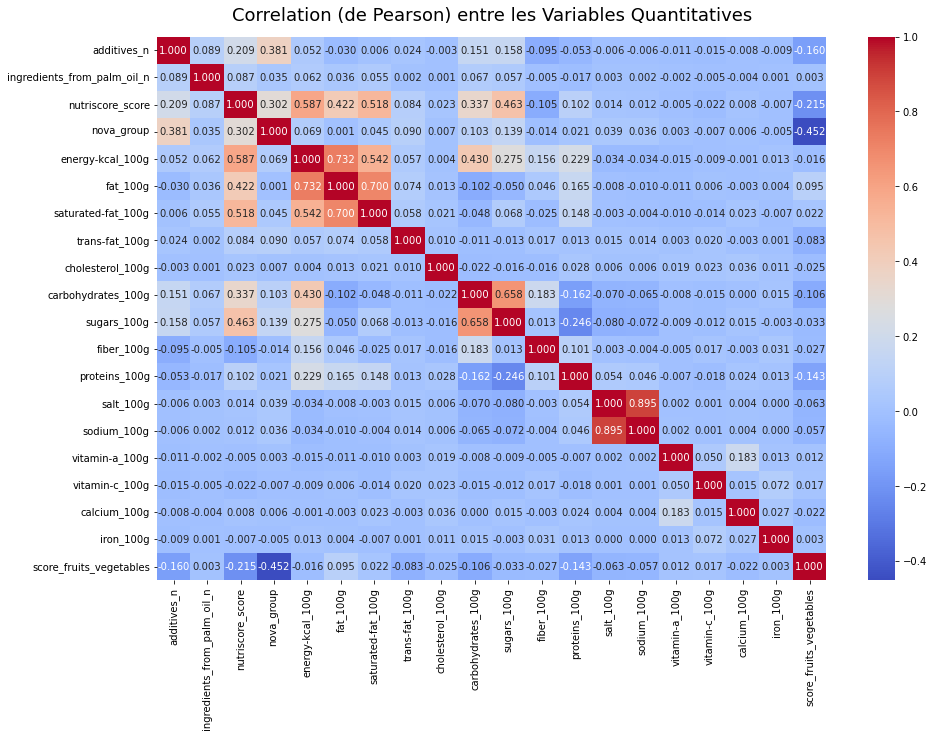

In [11]:
correlation_map_corr(df_net)

La heatmap ci-dessous donne les coefficients de corrélation de Pearson pour chaque couple de variables quantitatives.
Cette corrélation est linéaire, le coefficient est proche de 1 quand les variables partagent une forte corrélation linéaire.
Plusieurs observations peuvent être faites à partir de ce tableau.
- Les variables sodium_100g et salt_100g sont fortement corrélées (0.895).
- Les variables sugars_100g et carbohydrates_100g sont très corrélées entre elles et présentent une forte corrélation avec la variable nutriscore_score.
- Les variables fat_100g et saturated-fat_100g sont très corrélées (0.700) et des deux variables, c'est la variable fat_100g qui est le plus corrélées à energy-kcal_100g. En adéquation avec la façon de calculer le nutriscore, la variable saturated-fat_100g est davantage correlée à la variable nutriscore_score que la variable fat_100g.
Enfin, il est possible de voir une légère corrélation entre la variable score_fruits_vegetables et la variable nova_group. En effet, beaucoup de produits qui appartiennent à la catégorie des produits non ou peu transformés ont une grande proportion de fruits et légumes dans leur composition.

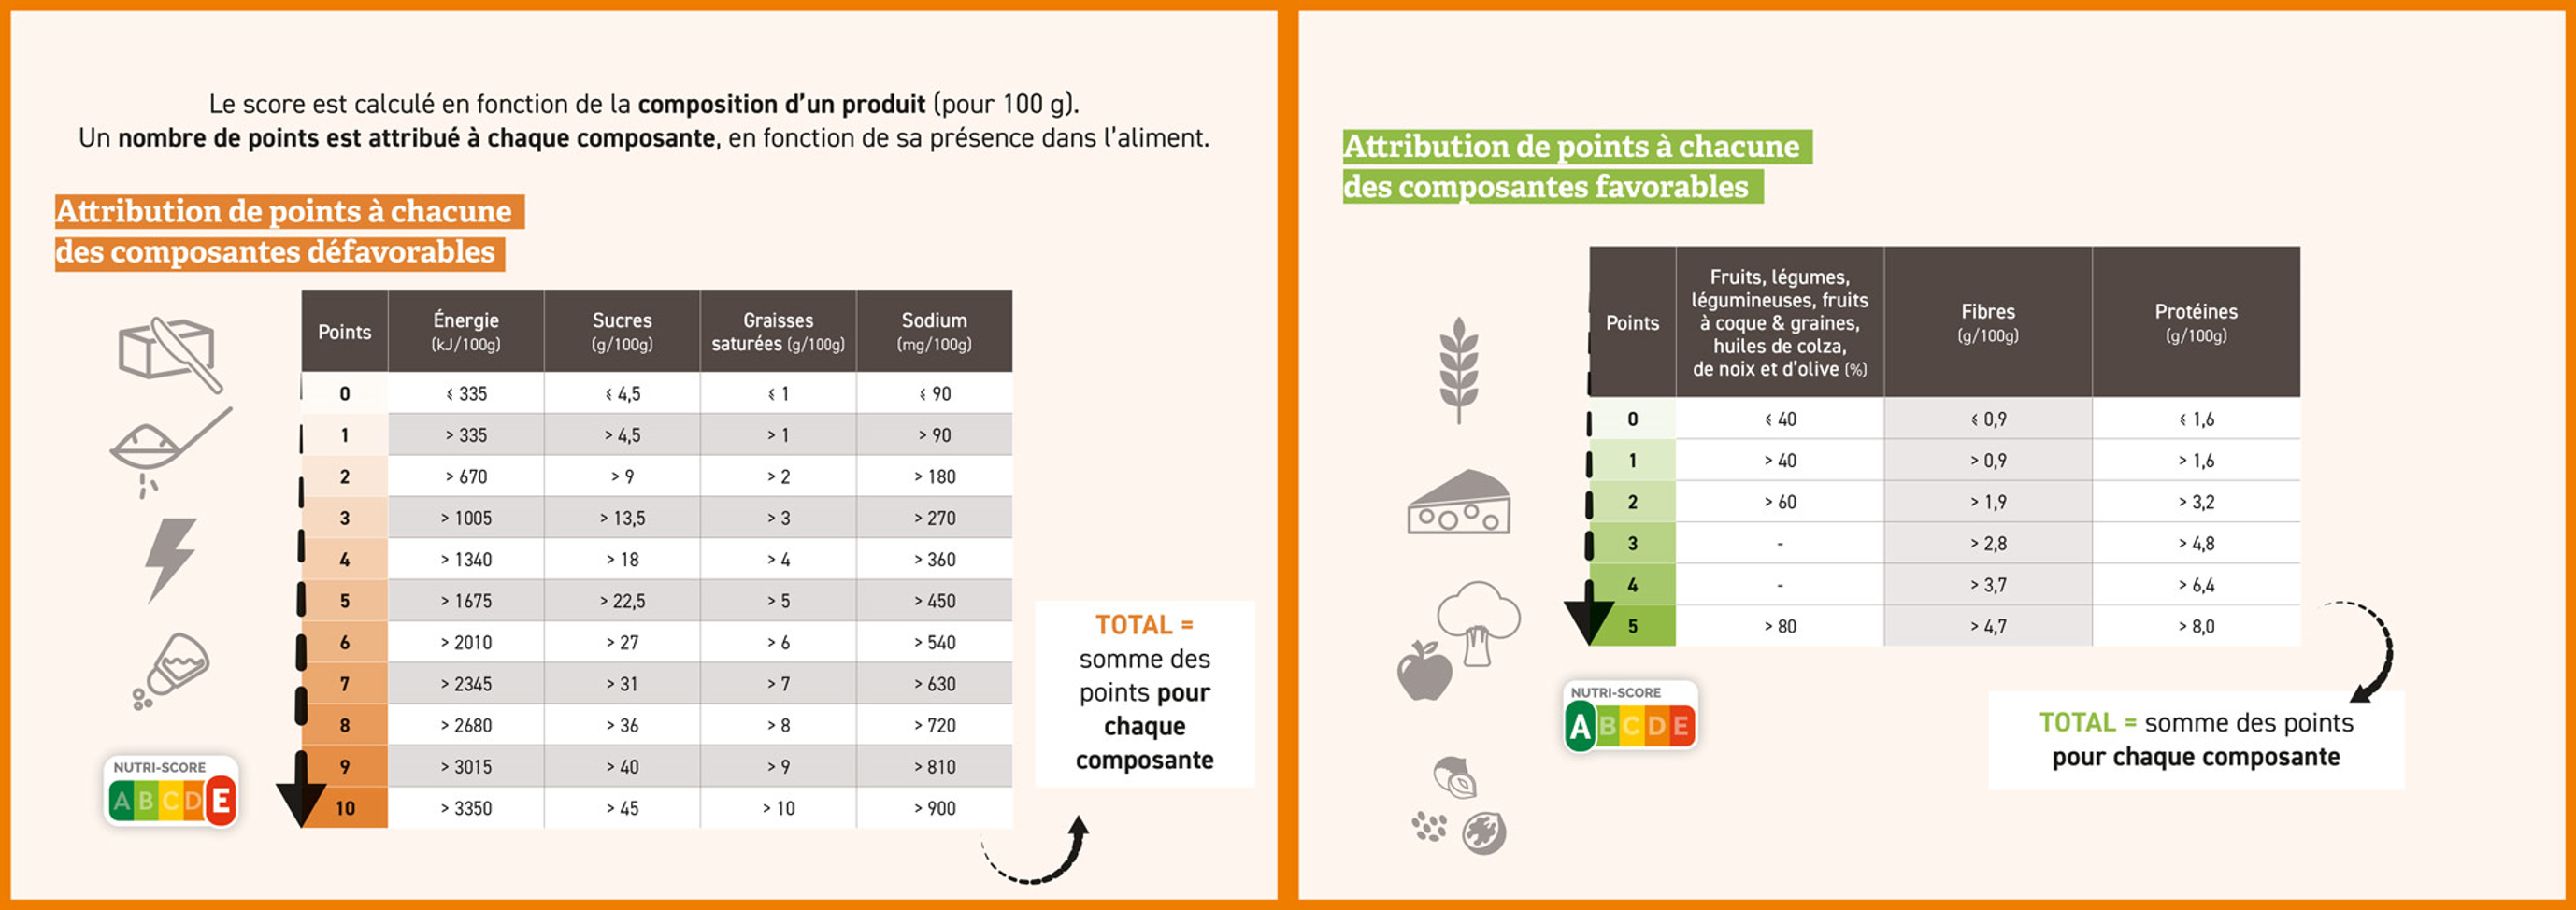

## Analyse en composantes principales (ACP)

L'analyse en composantes principales (ACP) a deux objectifs principaux :
- étudier la liaison entre les variables
- étudier la variabilité entre individus.
La premier objectif consiste à interpréter le cercle des correlations et de calculer les composantse principales.

In [12]:
df_net = df_net.drop(columns=[
    'created_t', 'energy_100g', 'serving_quantity',
    'ingredients_that_may_be_from_palm_oil_n', 'year'
])

In [13]:
data_pca = df_net.copy(deep=True)
data_pca = data_pca.drop(columns=[
    'score_fruits_vegetables', 'sodium_100g', 'saturated-fat_100g',
    'carbohydrates_100g'
])

print(
    f"La base de données contient {data_pca.select_dtypes(exclude=object).shape[1]} variables quantitatives"
)

La base de données contient 16 variables quantitatives


Avant de représenter les cercles de corrélations pour les différents couples d'axes principaux d'inertie, il faut connaître le nombre de composantes principales optimales.
Pour cela, la fonction ACP est utilisée pour le nombre total de variables quantitatives de la base de données. Pour avoir accès au nombre de composantes principales optimal il suffit de représenter l'éboulis des valeurs propres. Si le ratio d'inertie est inférieur à p/100 (où p est le nombre de variables quantitatives), cela signifie que l'axe principal d'inertie a moins de variabilité que la variable initiale (c'est le critère de Kaiser). Dans le cas de cette base de données, le nombre de composantes principales optimal est 6.

In [14]:
def maPCA(data_pca, n_comp):
    from sklearn import decomposition, preprocessing
    data = data_pca.copy(deep=True)
    data = data.select_dtypes(exclude=object)
    names = data.index
    X_scaled = preprocessing.StandardScaler().fit_transform(
        data.values)  #Preparation des données (centrées et réduites)
    pca = decomposition.PCA(n_components=n_comp)
    X_projected = pca.fit_transform(X_scaled)  #Projection des individus
    data_compo = pd.DataFrame(
        X_projected,
        index=data.index,
        columns=["F" + str(i + 1) for i in range(n_comp)])

    if n_comp < data_pca.select_dtypes(exclude=object).shape[1]:
        # Plotting principal components coefficient
        pcs = pca.components_
        df_pca_tab = pd.DataFrame(
            pcs,
            index=['F' + str(i + 1) for i in range(n_comp)],
            columns=data.columns).T
        heatmap = sns.heatmap(df_pca_tab,
                              annot=True,
                              fmt=".3f",
                              cmap='coolwarm')
        heatmap.set_title('Coefficients de chaque composante principale',
                          fontdict={'fontsize': 18},
                          pad=16)

    return pca, data_compo, n_comp, X_projected, names

In [15]:
pca, data_compo, n_comp, X_projected, names = maPCA(
    data_pca,
    data_pca.select_dtypes(exclude=object).shape[1])

In [16]:
def eboulis(pca, var_ini, n_comp):
    #Eboulis des valeurs propres
    eboulis = pca.explained_variance_ratio_ * 100

    plt.rcParams["figure.figsize"] = (8, 8)
    plt.bar(np.arange(len(eboulis)) + 1, eboulis)
    plt.plot(np.arange(len(eboulis)) + 1,
             eboulis.cumsum(),
             c="red",
             marker='o')

    plt.axhline(y=100 / var_ini, color='g')
    plt.text(n_comp / 2,
             eboulis[len(eboulis) // 2] + 5,
             "Seuil 100/p",
             fontsize=20,
             color='g')

    plt.xlabel("Rang de l'axe d'inertie")
    plt.ylabel("Pourcentage d'inertie (%)")
    plt.title("Eboulis des valeurs propres")
    plt.show(block=False)

    nb_composantes = [i for i in eboulis if i >= 100 / var_ini]

    print(
        f"D'après le critère de Kaiser, il y a {len(nb_composantes)} composantes principales optimales (avec un pourcentage d'inertie supérieur au seuil de 100/p)."
    )

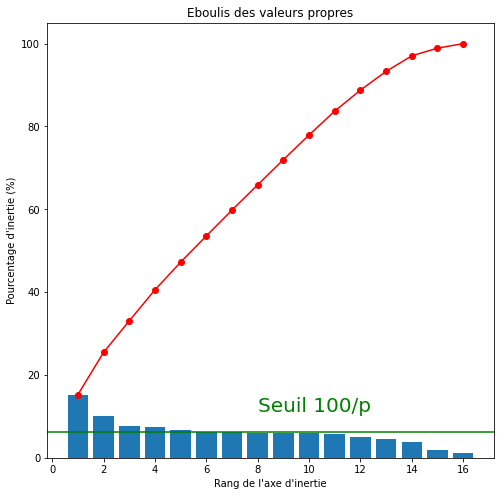

D'après le critère de Kaiser, il y a 6 composantes principales optimales (avec un pourcentage d'inertie supérieur au seuil de 100/p).


In [17]:
eboulis(pca, data_pca.select_dtypes(exclude=object).shape[1], n_comp)

Une fois le nombre de composantes principales optimal déterminé, il suffit d'appliquer à nouveau la fonction de l'ACP. Elle donne un tableau avec les coefficients de chaque composante principale.

Par exemple, la composante F1 est calculée comme suit :
    F1 = 0.181 * "additives_n" + 0.094 "ingredients_from_palm_oil" etc ....
Grâce à la heatmap il est possible de voir à quels axes principaux d'inertie les variables initiales sont fortement corrélées.
Par exemple, les variables "nutriscore_score" et "energy-kcal_100g" sont fortement corrélées à l'axe principale d'inertie F1. L'axe F1 pourrait représenter la proportion de mauvaises graisses dans le produit.
La variable "cholesterol_100g" est fortement anti-correlée à l'axe principale d'inertie F6 alors que la variable "fiber_100g" lui est fortement corrélée. Cet axe pourrait représenter l'effet bénéfique du produit sur la santé.

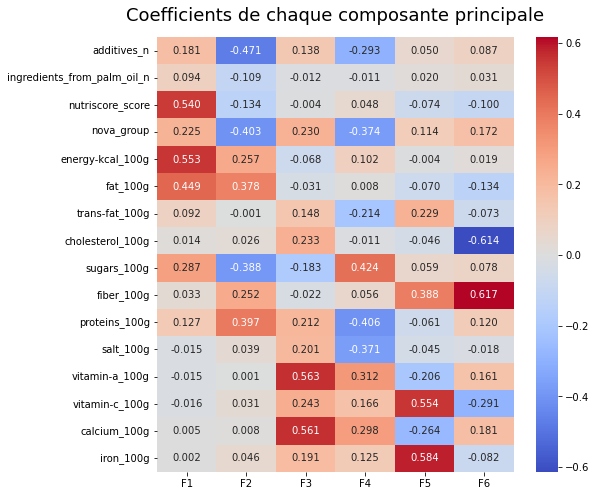

In [18]:
pca, data_compo, n_comp, X_projected, names = maPCA(data_pca, 6)

La fonction de l'ACP donne également le tableau de valeur selon les nouvelles "variables" que sont les composantes principales.

In [19]:
data_compo.head()

,F1,F2,F3,F4,F5,F6
0,0.642740,-0.266554,0.096669,-0.030729,0.184922,0.163366
1,-0.531045,-0.045014,0.450262,-0.731412,0.176831,0.294280
2,2.442821,1.180654,0.240600,-0.444187,0.010986,0.153695
3,0.371162,-0.560237,-0.278843,0.115846,-0.592942,-0.665881
4,-2.070200,-0.646187,0.248235,-0.383116,0.377463,0.235699


Les cercles des corrélations permettent de visualiser les corrélations entre les variables et les axes principaux d'inertie. Dans le cas de cette étude, l'analyse est une ACP normée, les axes vont donc de la valeur -1 à la valeur 1 et les flèches les plus faciles à interpréter sont celles dont la pointe est proche du cercle des corrélations.
Par exemple, sur le premier cercle, les deux flèches les plus faciles à interpréter sont celles des variables "nutriscore_score" et "energy-kcal_100g". Elles sont toutes les deux proches de l'axe principal d'inertie F1, elles ont donc un mode en commun avec cette composante principale.
Sur le troisième cercle, la flèche de la variable cholesterol_100g est proche de l'axe principal d'inertie F6, la variable est anti-corrélée à la composante principale F6 et la variable "fiber_100g" lui est fortement corrélée. Comme évoqué précédemment, cet axe pourrait représenter l'effet bénéfique du produit sur la santé.

In [20]:
def display_circles(n_comp,
                    pca,
                    axis_ranks,
                    labels=None,
                    label_rotation=0,
                    lims=None):
    from matplotlib.collections import LineCollection
    # Cercle des corrélations
    pcs = pca.components_

    for d1, d2 in axis_ranks:  # On affiche les n_comp/2 premiers plans factoriels, donc les n_comp premières composantes
        if d2 < n_comp:

            # initialisation de la figure
            fig, ax = plt.subplots(figsize=(10, 10))

            # détermination des limites du graphique
            if lims is not None:
                xmin, xmax, ymin, ymax = lims
            elif pcs.shape[1] < 30:
                xmin, xmax, ymin, ymax = -1, 1, -1, 1
            else:
                xmin, xmax, ymin, ymax = min(pcs[d1, :]), max(pcs[d1, :]), min(
                    pcs[d2, :]), max(pcs[d2, :])

            # affichage des flèches
            # s'il y a plus de 30 flèches, on n'affiche pas le triangle à leur extrémité
            if pcs.shape[1] < 30:
                plt.quiver(np.zeros(pcs.shape[1]),
                           np.zeros(pcs.shape[1]),
                           pcs[d2, :],
                           pcs[d1, :],
                           angles='xy',
                           scale_units='xy',
                           scale=1,
                           color="grey")
                # (voir la doc : https://matplotlib.org/api/_as_gen/matplotlib.pyplot.quiver.html)
            else:
                lines = [[[0, 0], [x, y]] for x, y in pcs[[d1, d2]].T]
                ax.add_collection(
                    LineCollection(lines, axes=ax, alpha=.1, color='black'))

            # affichage des noms des variables
            if labels is not None:
                for i, (x, y) in enumerate(pcs[[d2, d1]].T):
                    if x >= xmin and x <= xmax and y >= ymin and y <= ymax:
                        plt.text(x,
                                 y,
                                 labels[i],
                                 fontsize='14',
                                 ha='center',
                                 va='center',
                                 rotation=label_rotation,
                                 color="blue",
                                 alpha=0.5)

            # affichage du cercle
            circle = plt.Circle((0, 0), 1, facecolor='none', edgecolor='b')
            plt.gca().add_artist(circle)

            # définition des limites du graphique
            plt.xlim(xmin, xmax)
            plt.ylim(ymin, ymax)

            # affichage des lignes horizontales et verticales
            plt.plot([-1, 1], [0, 0], color='grey', ls='--')
            plt.plot([0, 0], [-1, 1], color='grey', ls='--')

            # nom des axes, avec le pourcentage d'inertie expliqué
            plt.xlabel('F{} ({}%)'.format(
                d1 + 1, round(100 * pca.explained_variance_ratio_[d1], 1)))
            plt.ylabel('F{} ({}%)'.format(
                d2 + 1, round(100 * pca.explained_variance_ratio_[d2], 1)))

            plt.title("Cercle des corrélations (F{} et F{})".format(
                d1 + 1, d2 + 1))
            plt.show(block=False)

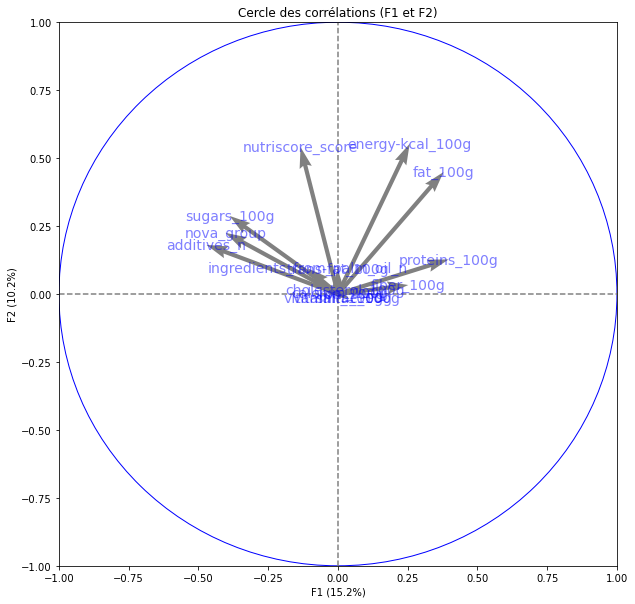

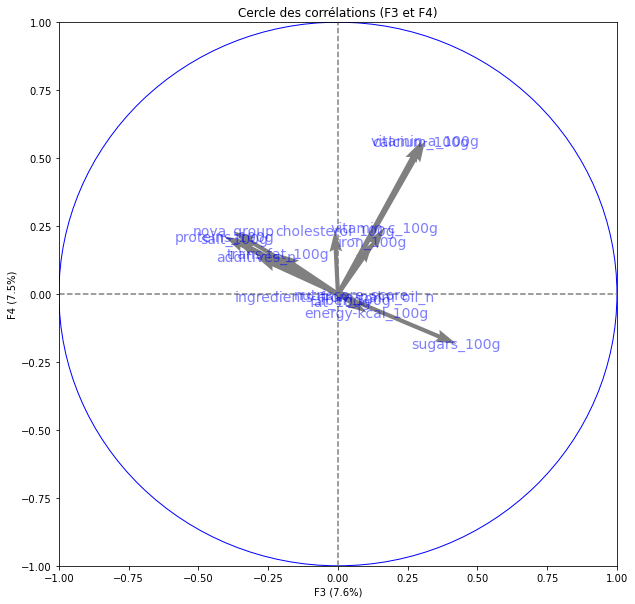

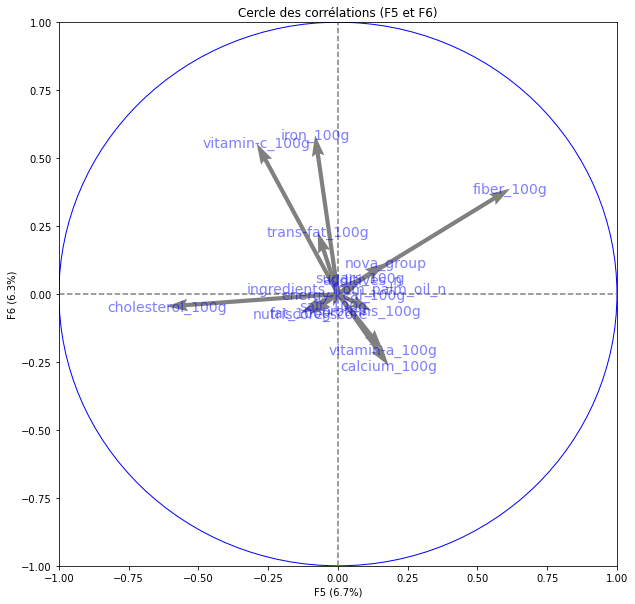

In [21]:
features = data_pca.select_dtypes(exclude=object).columns
display_circles(n_comp,
                pca, [(0, 1), (2, 3), (4, 5)],
                labels=np.array(features))

Enfin il est possible de représenter les produits sur les graphiques avec comme axes les composantes principales. Celà permet de voir s'il est possible de dégager des tendances ou des groupes suivant ces nouvelles "variables.
Dans le cas de cette étude, par exemple pour la variable nutriscore, il n'est pas évident de voir des groupes se détacher ou des tendances particulières.

In [22]:
def display_factorial_planes(X_projected,
                             n_comp,
                             pca,
                             axis_ranks,
                             labels=None,
                             alpha=1,
                             illustrative_var=None):

    X_pro = pd.DataFrame(X_projected,
                         columns=["F" + str(i + 1) for i in range(n_comp)])
    for col in X_pro.columns:
        X_pro[col] = (X_pro[col] - X_pro[col].mean()) / (X_pro[col].max() -
                                                         X_pro[col].min())
    X_projected = X_pro.to_numpy()

    for d1, d2 in axis_ranks:
        if d2 < n_comp:

            # initialisation de la figure
            plt.figure(figsize=(7, 6))

            # affichage des points
            if illustrative_var is None:
                plt.scatter(X_projected[:, d1],
                            X_projected[:, d2],
                            alpha=alpha)
            else:
                illustrative_var = np.array(illustrative_var)
                for value in np.unique(illustrative_var):
                    selected = np.where(illustrative_var == value)
                    plt.scatter(X_projected[selected, d1],
                                X_projected[selected, d2],
                                alpha=alpha,
                                label=value)
                plt.legend()

            # affichage des labels des points
            if labels is not None:
                for i, (x, y) in enumerate(X_projected[:, [d1, d2]]):
                    plt.text(x,
                             y,
                             labels[i],
                             fontsize='14',
                             ha='center',
                             va='center')

            # détermination des limites du graphique
            boundary = np.max(np.abs(X_projected[:, [d1, d2]])) * 1.1
            plt.xlim([-1, 1])
            plt.ylim([-1, 1])

            # affichage des lignes horizontales et verticales
            plt.plot([-100, 100], [0, 0], color='grey', ls='--')
            plt.plot([0, 0], [-100, 100], color='grey', ls='--')

            # nom des axes, avec le pourcentage d'inertie explicité
            plt.xlabel('F{} ({}%)'.format(
                d1 + 1, round(100 * pca.explained_variance_ratio_[d1], 1)))
            plt.ylabel('F{} ({}%)'.format(
                d2 + 1, round(100 * pca.explained_variance_ratio_[d2], 1)))

            plt.title("Projection des individus (sur F{} et F{})".format(
                d1 + 1, d2 + 1))
            plt.show(block=False)

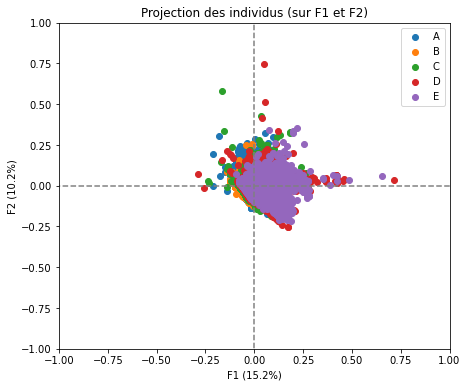

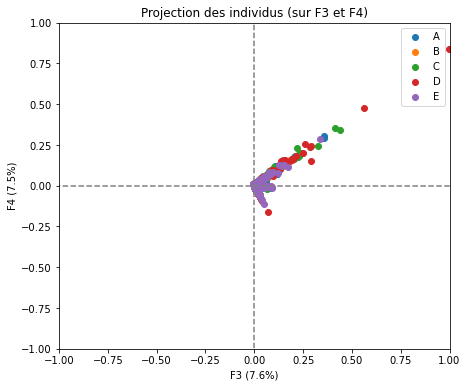

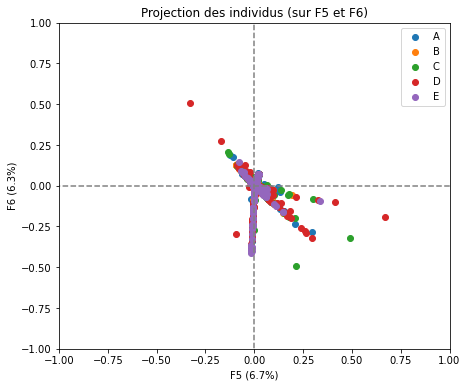

In [23]:
#Si besoin de faire un échantillon pour faciliter les calculs :
#X_projected = pd.DataFrame(X_projected, columns=["F" + str(i + 1) for i in range(n_comp)])
#X_projected=X_projected.sample(100000)
#X_projected=X_projected.to_numpy()
display_factorial_planes(X_projected,
                         n_comp,
                         pca, [(0, 1), (2, 3), (4, 5)],
                         illustrative_var=data_pca['nutriscore_grade'])

## Partitionner avec l'algorithme  k-means

L'algorithme k-means permet de regrouper les données en un certain nombre de groupes (clusters). Les points de chaque groupe partagent des tendances, des modes en commun. Pour trouver le nombre de groupes optimal, il faut utiliser les coordonnées des points projetés sur les composantes principales déterminées grâce à l'ACP. Pour trouver ce nombre optimal de clusters, la méthode du coude est utilisé.

In [24]:
#Utiliser la méthode du coude pour déterminer le nombre optimum de clusters


def methode_coude(X_projected):

    from sklearn.cluster import KMeans

    wcss = []
    for i in range(1, 11):
        km = KMeans(n_clusters=i)
        km.fit(X_projected)
        wcss.append(km.inertia_)
    plt.plot(range(1, 11), wcss)
    plt.title('Méthode du coude')
    plt.xlabel('Nombre de clusters')
    plt.ylabel('Distortion')
    plt.show()

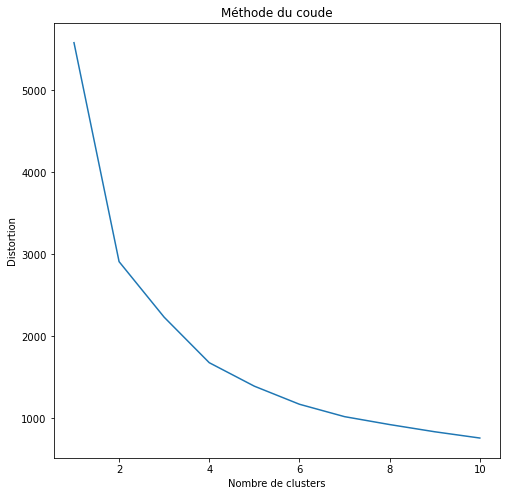

In [25]:
methode_coude(X_projected)

Ici l'algorithme des k-means a été lancé avec plusieurs valeurs de K (nombre de clusters). Le nombre de clusters est représenté en abscisse. Chaque calcul donne K groupes avec un "centroid" pour chaque groupe. La variance est la somme des distances entre le centroid et les points du groupe. Pour trouver le bon nombre de clusters il faut minimiser ces distances (les distances intra-classes). En suivant la méthode du coude, le nombre K choisi est celui à partir duquel la variance (distortion sur le graphique) ne se réduit plus de façon significative. Sur ce graphique il se trouve à 2 ou à 6. Le choix se porte sur 6 car 2 ne serait pas un nombre de groupes suffisant étant donné la grande variation de nos produits.

In [26]:
## KMeans Clustering


def clusters(n_clust, X_projected, data_pca):
    from sklearn.cluster import KMeans

    km = KMeans(n_clusters=n_clust).fit(X_projected)
    clustK = km.labels_

    return clustK

In [27]:
data_pca['cluster_Kmeans'] = clusters(6, X_projected, data_pca)

La segmentation des données est faite grâce aux fonctions Kmeans. Les différents produits de la base de données sont partagés en 8 sous-groupes en fonction de leur projection sur les composantes principales. Une colonne avec le numéro du groupe est ajoutée à la base de données. Comme il a été fait pour essayer de distinguer les nutriscores sur les valeurs projetées sur les axes principaux d'inertie, les valeurs projetées sont cette fois-ci différenciées par leur groupe K d'appartenance.

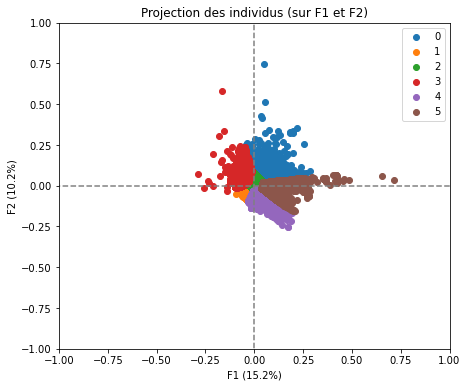

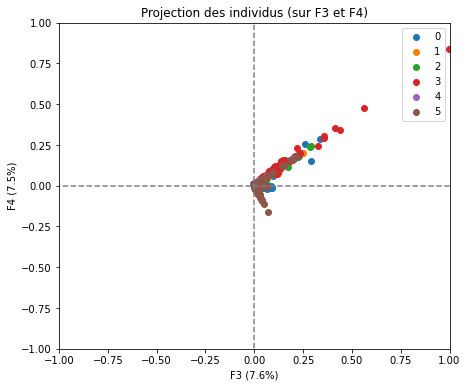

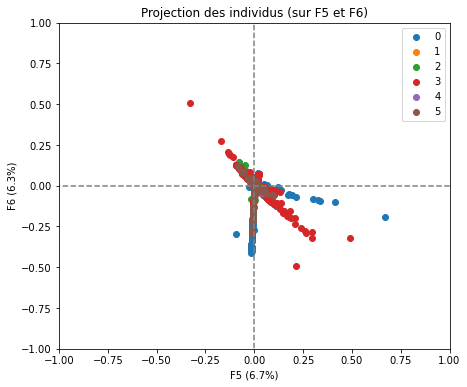

In [28]:
display_factorial_planes(X_projected,
                         n_comp,
                         pca, [(0, 1), (2, 3), (4, 5)],
                         illustrative_var=data_pca['cluster_Kmeans'])

Contrairement aux représentations précédentes, les groupes sont ici visibles, notamment sur la représentation des projections sur les composantes F1 et F2. 
Cette association de l'analyse en composantes principales avec l'algorithme de k-means représente une opportunitée pour commencer une classification non supervisée. Cette classification pourra ensuite être utilisée par des algorithmes pour prédire des valeurs de variables telles que les valeurs d'un nutriscore ou pour savoir à quel groupe d'aliments appartient un produit à partir de ces variables quantitatives.

# Analyses explicatives

## une variable quantitative et une variable qualitative : ANOVA

Les tests ANOVA permettent de comparer des variables quantitatives à des variables qualitatives. Une partie des variables est sélectionnée pour ces tests.

In [29]:
columns_quali = [
    'labels_tags', 'nutriscore_grade', 'pnns_groups_1', 'countries'
]
columns_quanti = [
    'nutriscore_score', 'energy-kcal_100g', 'fat_100g', 'sugars_100g',
    'fiber_100g', 'proteins_100g', 'salt_100g'
]
df_anova = df_net[columns_quali + columns_quanti]

La corrélation entre des variables quantitatives et des variables qualitatives peut être observée grâce à des représentations de type pairplot.

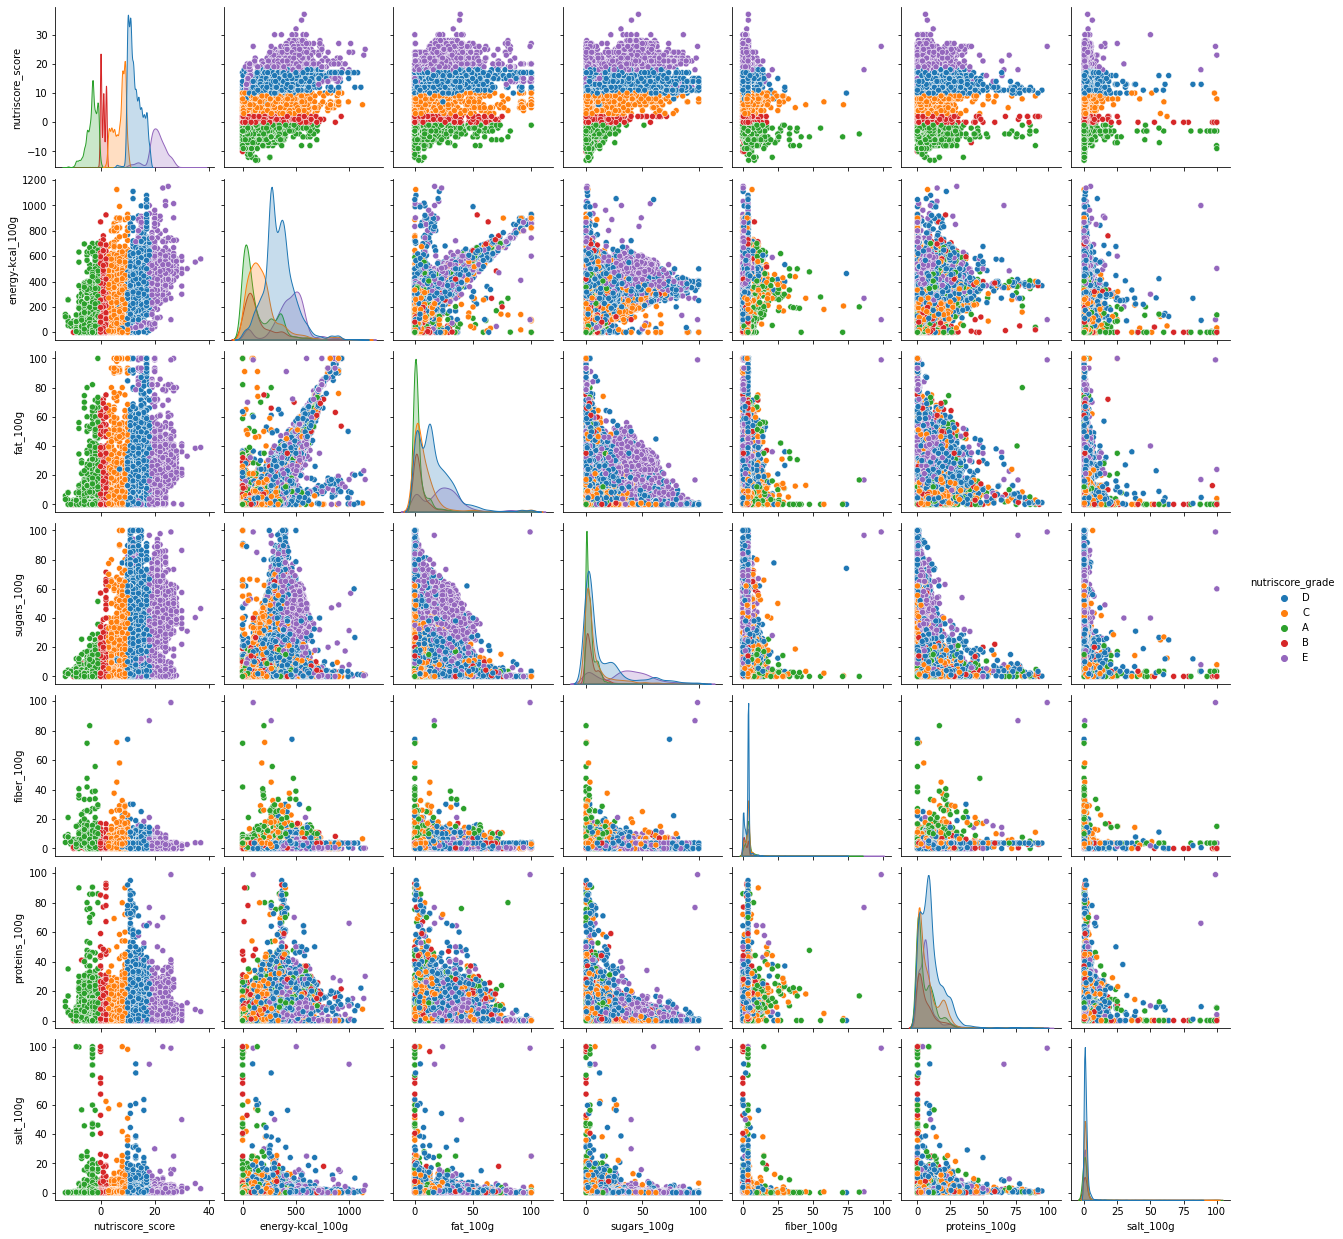

In [30]:
sns.pairplot(df_anova.sample(frac=0.01), hue="nutriscore_grade")
plt.show()

Sur ces représentations, il est possible de voir une répartition des nutriscore_grade en fonction des valeurs de sugars_100g, fat_100g et energy-kcal_100g.

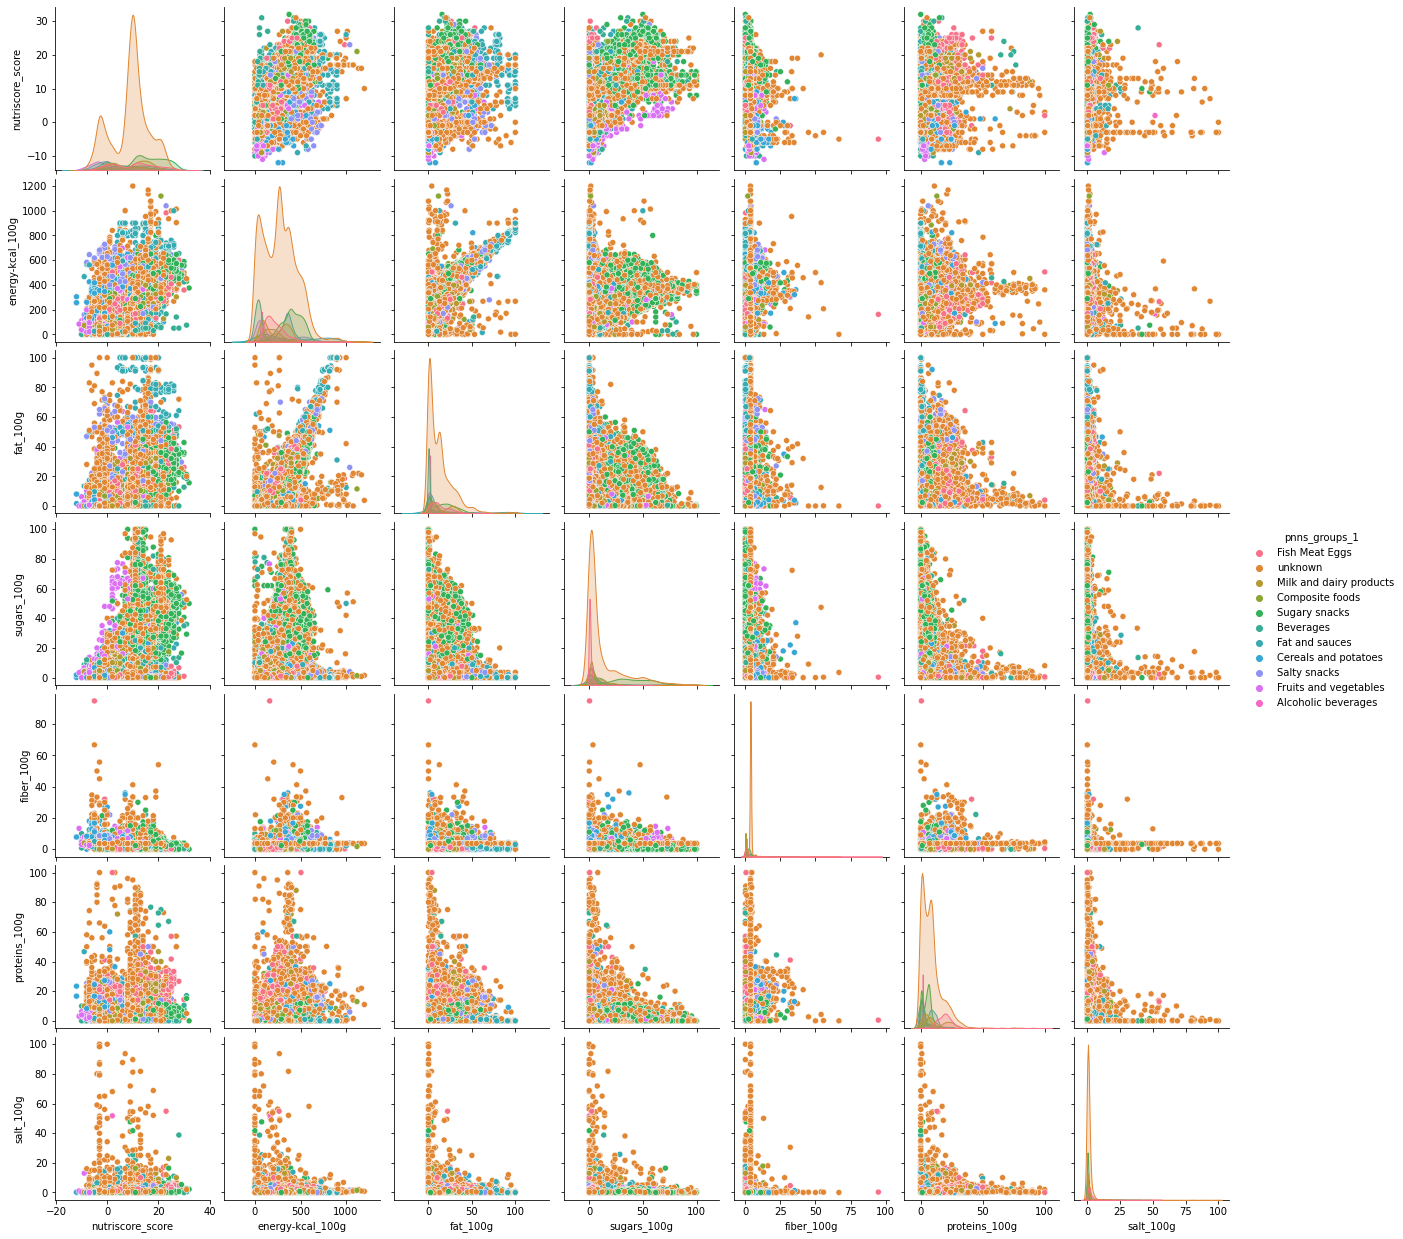

In [31]:
sns.pairplot(df_anova.sample(frac=0.01), hue="pnns_groups_1")
plt.show()

Néanmoins, sur les pairplots des groupes pnns_groups_1 il est difficile de distinguer des tendances. D'une part, parce qu'il y a beaucoup plus de modalités différentes (5 pour nutriscore_grade, 10 pour pnns_groups_1). D'autre part, la variable pnns_groups_1 contient une grande proportion de "unknown", ce qui masque les points des autres groupes de produits. Il est possible de tracer le même type de courbes sans ces valeurs.

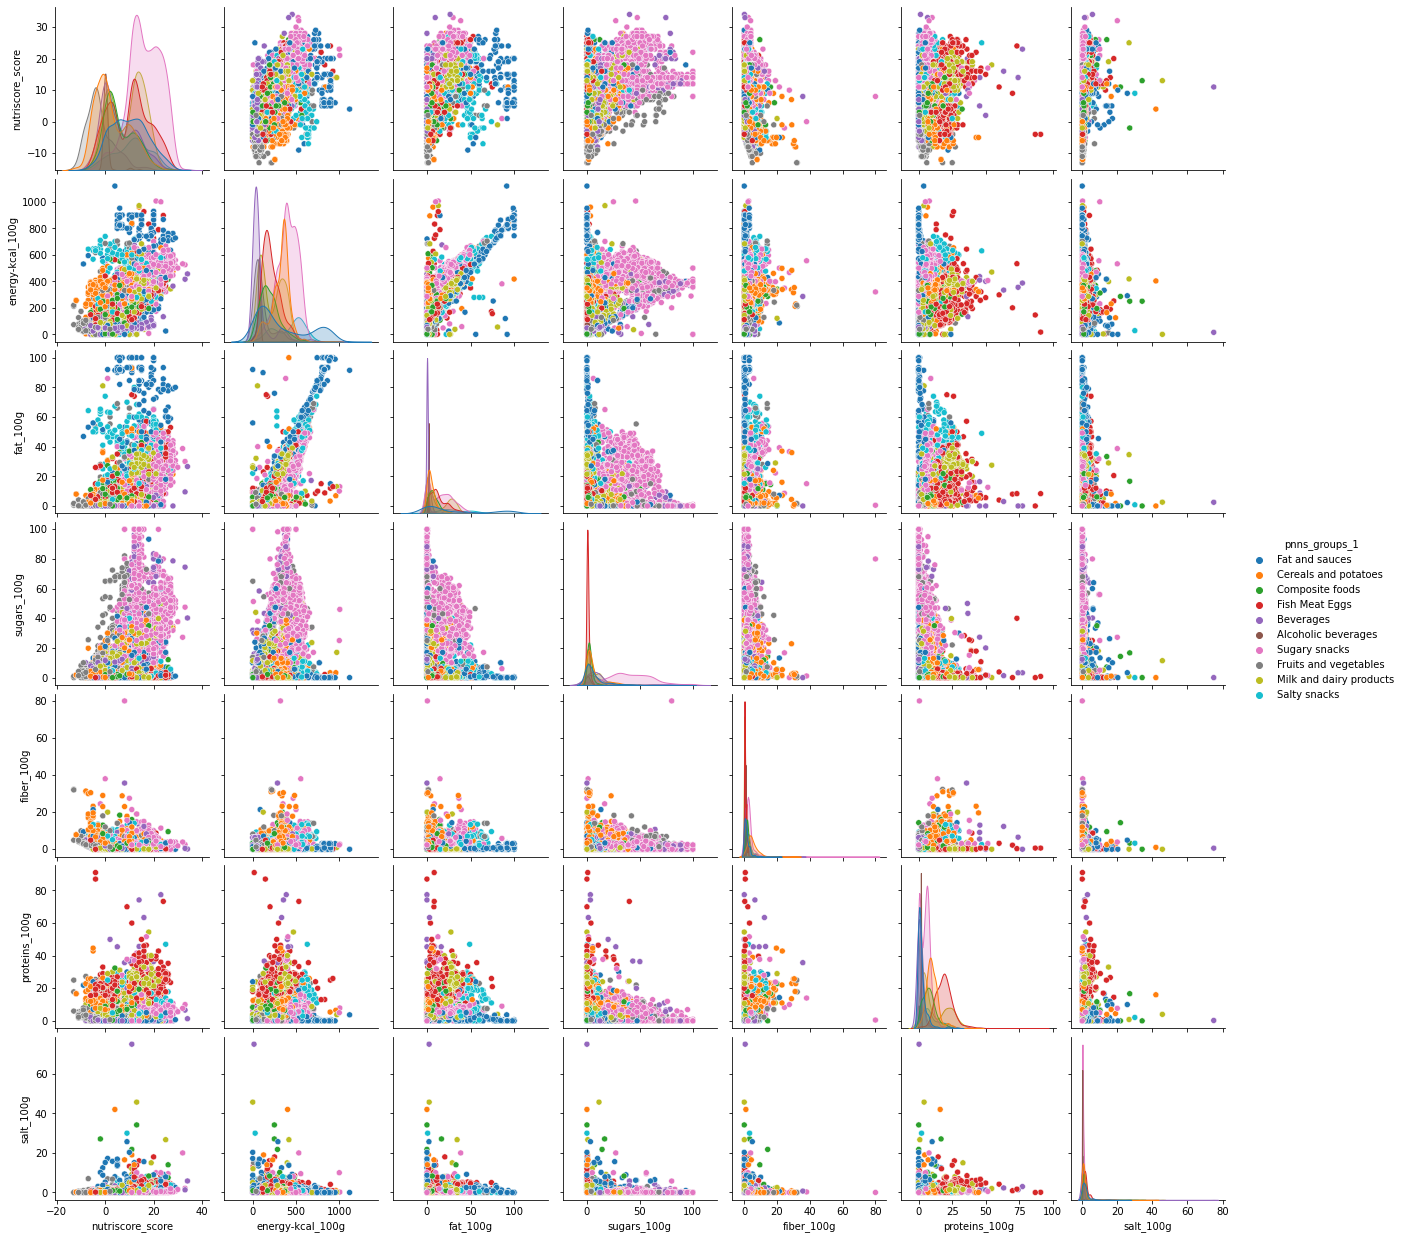

In [32]:
data = df_anova.copy(deep=True)
data = data.drop(data[data.pnns_groups_1 == 'unknown'].index)
sns.pairplot(data.sample(frac=0.01), hue="pnns_groups_1")
plt.show()

Une autre façon de visualiser des corrélations entre les variables qualitatives et les variables quantitatives est de représenter des boxplots des variables quantitatives en fonction des modalités des variables qualitatives.

In [33]:
def moust_aqui(df_anova, columns_quali):

    for column_quali in columns_quali:
        order = sorted(list(set(df_anova[column_quali])))
        i = 0
        for column_quanti in columns_quanti:
            i += 1
            plt.rcParams["figure.figsize"] = (14, 8)
            plt.subplot(2, 4, i)
            sns.boxplot(x=column_quanti,
                        y=column_quali,
                        data=df_anova,
                        showfliers=False,
                        palette="colorblind",
                        orient="h",
                        order=order)
            plt.tight_layout()
        plt.show()

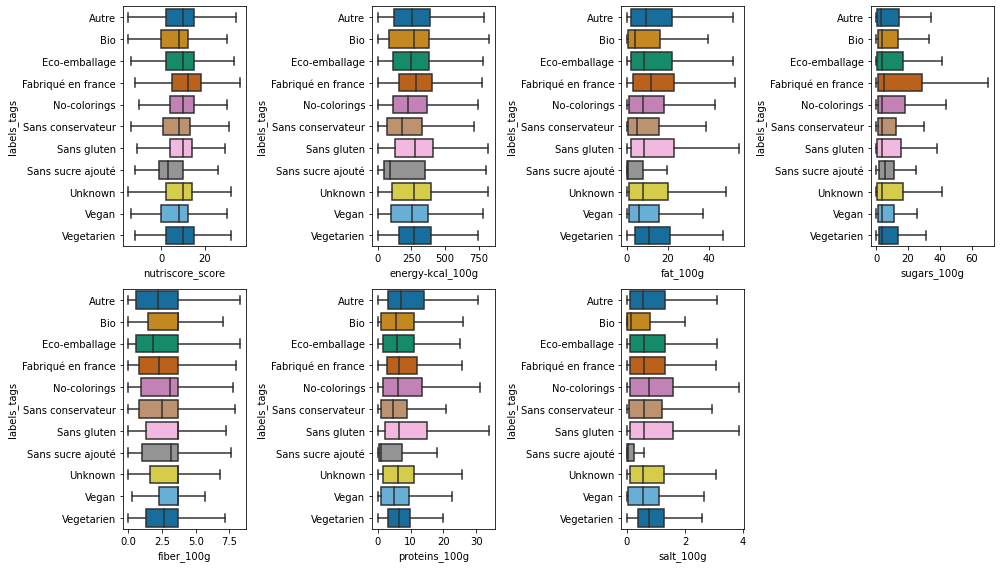

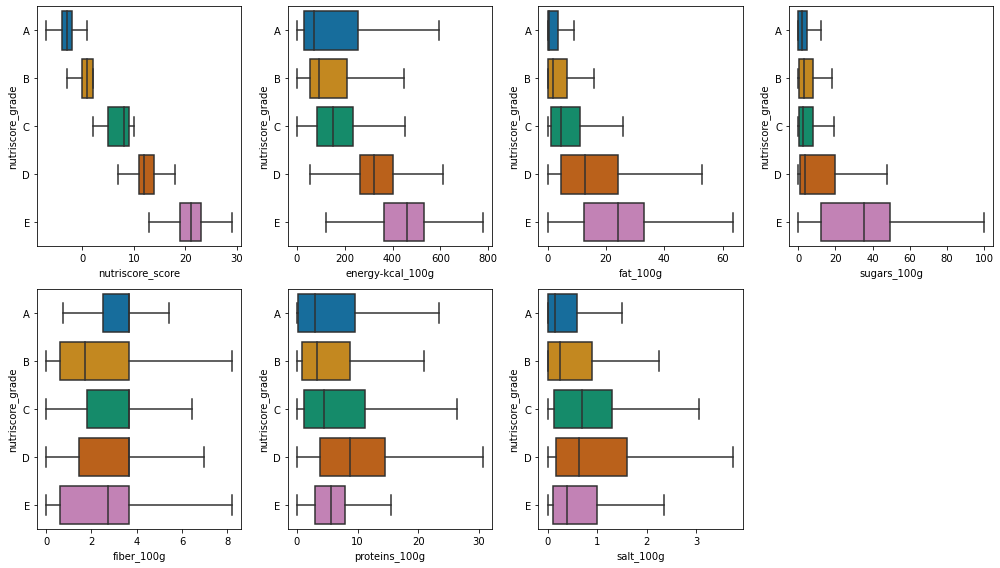

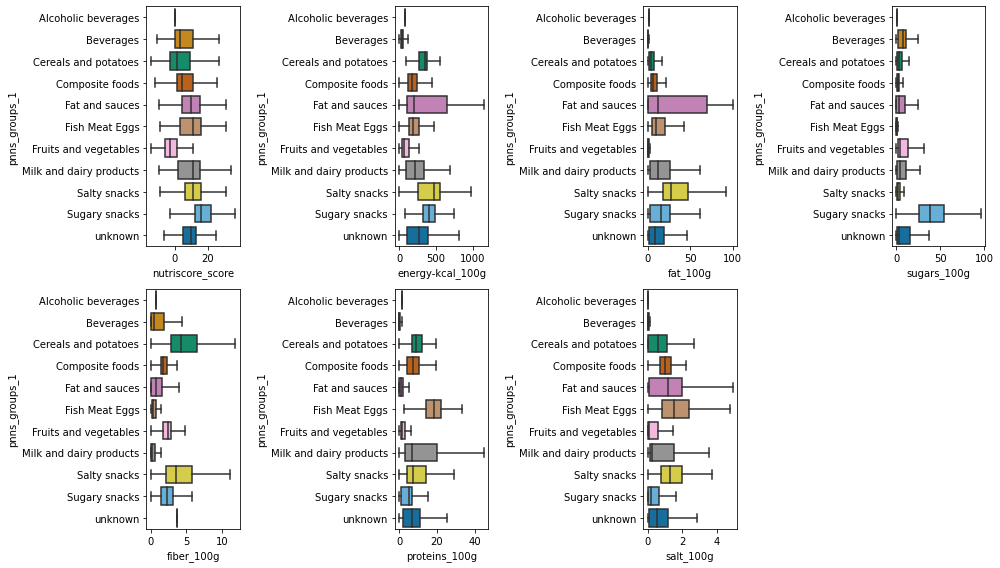

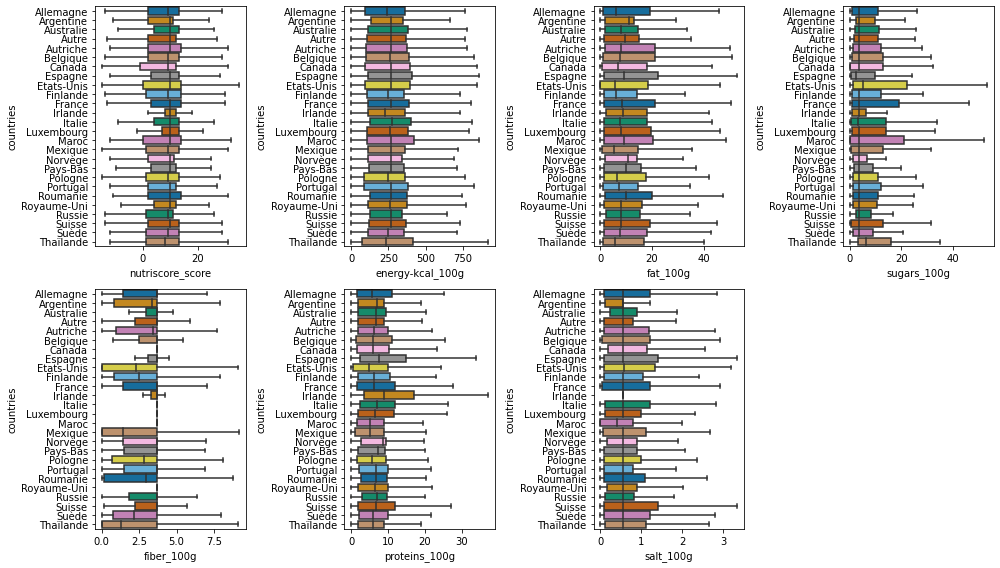

In [34]:
moust_aqui(df_anova, columns_quali)

De ces représentations plusieurs observations sont à retenir :
- la variable labels_tags a l'air relativement influencée par les variables quantitatives (notamment nucriscore_score, fat_100g, proteins_100g et salt_100g)
- la variable nutriscore_grade est fortement influencée par toutes les variables quantitatives (ce qui n'est pas surprenant étant donné que son calcul en dépend)
- la variable pnns_groups_1 est très fortement influencée par toutes les variables quantitatives.
- la variable countries n'a pas l'air influencée par les variables quantitatives.

In [35]:
def eta_squared(df, X, Y):
    #X = qualitative
    #Y = quantitative
    moyenne_y = df[Y].mean()
    classes = []
    for classe in df[X].unique():
        yi_classe = df[Y][df[X] == classe]
        classes.append({
            'ni': len(yi_classe),
            'moyenne_classe': yi_classe.mean()
        })
    SCT = sum([(yj - moyenne_y)**2 for yj in df[Y]])
    SCE = sum(
        [c['ni'] * (c['moyenne_classe'] - moyenne_y)**2 for c in classes])
    #print(X, 'vs', Y, 'eta_squared = ', round(SCE/SCT,3))
    return SCE / SCT

In [36]:
def tableau_eta(df_anova, columns_quali, columns_quanti):

    eta = []
    for column_quanti in columns_quanti:
        for column_quali in columns_quali:
            eta.append(
                round(eta_squared(df_anova, column_quali, column_quanti), 3))
    nb_col = len(columns_quali)
    data_eta = {
        columns_quanti[0]: eta[0:nb_col],
        columns_quanti[1]: eta[nb_col:(nb_col * 2)],
        columns_quanti[2]: eta[2 * nb_col:nb_col * 3],
        columns_quanti[3]: eta[3 * nb_col:nb_col * 4],
        columns_quanti[4]: eta[4 * nb_col:nb_col * 5],
        columns_quanti[5]: eta[5 * nb_col:nb_col * 6],
        columns_quanti[6]: eta[6 * nb_col:nb_col * 7]
    }

    return data_eta

In [37]:
data_eta = tableau_eta(df_anova, columns_quali, columns_quanti)

Le tableau ci-dessous représente les rapports de corrélation (Variation interclasses / Variation totale) pour chaque couple de variables.

In [38]:
df_resultat = pd.DataFrame(data_eta, index=columns_quali)
display(df_resultat)

,nutriscore_score,energy-kcal_100g,fat_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g
labels_tags,0.008,0.002,0.001,0.001,0.009,0.004,0.001
nutriscore_grade,0.909,0.325,0.153,0.239,0.031,0.042,0.002
pnns_groups_1,0.199,0.165,0.132,0.240,0.177,0.146,0.011
countries,0.004,0.002,0.002,0.009,0.005,0.008,0.002


Plus le rapport de corrélation est proche de 1, plus les variables sont fortement corrélées. Il est possible d'observer que les deux variables qui visuellement avaient l'air fortement corrélées aux variables quantitatives le sont dans ce tableau (nutriscore_grade et pnns_groups_2). Finalement, la variable labels_tags n'est pas aussi influencée que ce qui était attendu. Enfin, le tableau confirme que la variable countries n'est que très faiblement influencée par les variables quantitatives. Néanmoins, ces deux variables sont-elles peu influencées ou sont-elles complètement indépendantes? Les tests ANOVA vont aider à répondre à cette question.

Les deux hypothèses du test ANOVA effectué sur cette étude sont :
- H0 : les distributions suivent la même loi normale. 
- H1 : il existe au moins une distribution dont la moyenne s'écarte des autres moyennes.

Avant de lancer un test ANOVA, il est indispensable de vérifier si les variables quantitatives répondent à une loi normale.

In [39]:
def test_anova_data(data):
    from scipy import stats
    numeric_columns = data.select_dtypes(exclude=object).columns
    for column in numeric_columns:
        print('________\n{}'.format(column))
        k2, p = stats.normaltest(data[column], axis=0, nan_policy='omit')
        alpha = 5e-2
        print("p = {:g}".format(p))
        if p < alpha:  # null hypothese: x a une distribution normale
            print(
                "H0 est rejetée : {} n'est pas de distribution normale".format(
                    column))
        else:
            print(
                "H0 ne peut être rejetée :{}, on considère l'hypothèse de normalité"
                .format(column))

In [40]:
test_anova_data(df_anova)

________
nutriscore_score
p = 0
H0 est rejetée : nutriscore_score n'est pas de distribution normale
________
energy-kcal_100g
p = 0
H0 est rejetée : energy-kcal_100g n'est pas de distribution normale
________
fat_100g
p = 0
H0 est rejetée : fat_100g n'est pas de distribution normale
________
sugars_100g
p = 0
H0 est rejetée : sugars_100g n'est pas de distribution normale
________
fiber_100g
p = 0
H0 est rejetée : fiber_100g n'est pas de distribution normale
________
proteins_100g
p = 0
H0 est rejetée : proteins_100g n'est pas de distribution normale
________
salt_100g
p = 0
H0 est rejetée : salt_100g n'est pas de distribution normale


Pour chaque variable quantitative, l'hypothèse de distribution normale est rejétée. Les résultats des tests ANOVA seront donc à prendre avec précautions.

In [41]:
def table_anova(var, df_anova):
    #H0: "V1 et V2 sont INDEPENDANTS"
    # get ANOVA table as R like output
    import statsmodels.api as sm
    from statsmodels.formula.api import ols

    # Ordinary Least Squares (OLS) model
    model = ols(var, data=df_anova).fit()
    anova_table = sm.stats.anova_lm(model, typ=2)
    display(anova_table)
    #si p-value(PR(>F))<0.05 alors il y a dependance entre les deux variables

In [42]:
table_anova('nutriscore_score ~ C(pnns_groups_1)', df_anova)

,sum_sq,df,F,PR(>F)
C(pnns_groups_1),1.951734e+07,10.0,38051.353704,0.0
Residual,7.832649e+07,1527067.0,NaN,NaN


In [43]:
table_anova('nutriscore_score ~ C(countries)', df_anova)

,sum_sq,df,F,PR(>F)
C(countries),4.257988e+05,25.0,266.980075,0.0
Residual,9.741804e+07,1527052.0,NaN,NaN


In [44]:
table_anova('nutriscore_score ~ C(labels_tags)', df_anova)

,sum_sq,df,F,PR(>F)
C(labels_tags),7.464292e+05,10.0,1173.921621,0.0
Residual,9.709741e+07,1527067.0,NaN,NaN


In [45]:
table_anova('nutriscore_score ~ C(nutriscore_grade)', df_anova)

,sum_sq,df,F,PR(>F)
C(nutriscore_grade),8.895511e+07,4.0,3.820597e+06,0.0
Residual,8.888726e+06,1527073.0,NaN,NaN


Les tests d'indépendance (test de Fisher) de chacune des variables qualitatives donnent une p-value inférieure à 0.05 (niveau de test = 5%). L'hypothèse H0 selon laquelle les distributions par modalité présentent une similarité est rejetée. Cela signifie qu'il y a une dépendance entre les variables quantitatives et les variables qualitatives.

## Deux variables qualitatives : CHI-2

Le test du CHI-2 (ou KHI-2) est utilisé ici pour avoir une idée de la dépendance des variables qualitatives. Dans cette partie, seule la corrélation entre le nutriscore et les autres variables qualitatives sera étudiée.

In [46]:
columns_quali = [
    'labels_tags', 'nutriscore_grade', 'pnns_groups_1', 'countries'
]
columns_quali_sans_nutri = ['labels_tags', 'pnns_groups_1', 'countries']
df_chi_2 = df_net[columns_quali]
df_chi_2['pnns_groups_1'] = df_chi_2['pnns_groups_1'].str.capitalize()

C:\Users\smora\AppData\Local\Temp/ipykernel_11544/2464384396.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_chi_2['pnns_groups_1'] = df_chi_2['pnns_groups_1'].str.capitalize()


In [47]:
def visu_chi2(df_chi_2, columns_quali_sans_nutri):

    for column in columns_quali_sans_nutri:
        data = df_chi_2.copy(deep=True)
        data = data.drop(data[data[column] == 'Unknown'].index)
        sns.catplot(x='nutriscore_grade',
                    hue=column,
                    data=data,
                    kind="count",
                    order=['A', 'B', 'C', 'D', 'E'],
                    palette='colorblind')
        plt.rcParams["figure.figsize"] = (14, 8)
        plt.show()

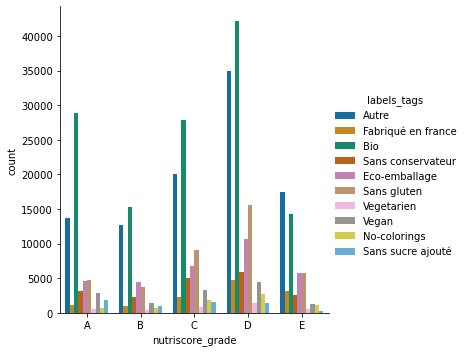

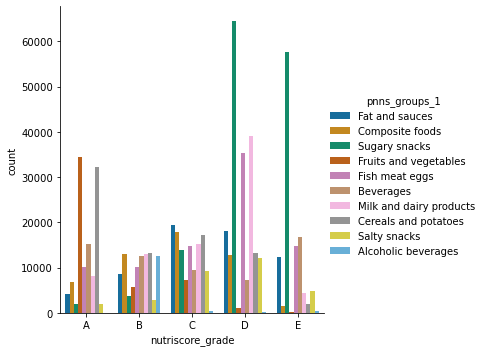

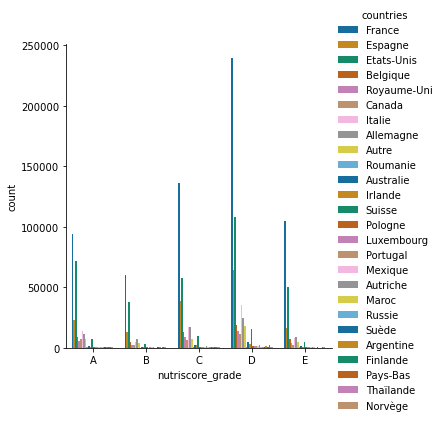

In [48]:
visu_chi2(df_chi_2, columns_quali_sans_nutri)

D'abord, un tableau de contingence est affiché pour chacune des variables. Il s'agit tu tableau où apparaissent les $n_{ij}$.

In [49]:
def tableau_contingence_XY(df, X, Y):
    contingence = df[[X,
                      Y]].pivot_table(index=X, columns=Y,
                                      aggfunc=len).fillna(0).copy().astype(int)
    display(contingence)
    return contingence

In [50]:
for column in columns_quali_sans_nutri:
    tableau = tableau_contingence_XY(df_chi_2, 'nutriscore_grade', column)

labels_tags,Autre,Bio,Eco-emballage,Fabriqué en france,No-colorings,Sans conservateur,Sans gluten,Sans sucre ajouté,Unknown,Vegan,Vegetarien
nutriscore_grade,,,,,,,,,,,
A,13708,28924,4570,1142,668,3198,4815,1832,197370,2881,541
B,12718,15365,4510,1031,772,2363,3803,984,102374,1465,460
C,20033,27802,6813,2316,1844,5001,9130,1590,248186,3309,886
D,34929,42156,10657,4755,2748,5876,15618,1486,451934,4512,1412
E,17418,14252,5748,3122,1095,2545,5804,332,166544,1222,509


pnns_groups_1,Alcoholic beverages,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish meat eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks,Unknown
nutriscore_grade,,,,,,,,,,,
A,78,15196,32141,6910,4071,10057,34475,8198,2060,1968,144495
B,12588,12622,13304,13100,8554,10145,5668,13023,2867,3756,50218
C,315,9451,17134,17888,19465,14669,7256,15319,9279,13811,202323
D,89,7241,13304,12796,18074,35302,1096,39058,12162,64469,372492
E,469,16729,2069,1559,12391,14671,114,4346,4731,57555,103957


countries,Allemagne,Argentine,Australie,Autre,Autriche,Belgique,Canada,Espagne,Etats-Unis,Finlande,...,Norvège,Pays-Bas,Pologne,Portugal,Roumanie,Royaume-Uni,Russie,Suisse,Suède,Thaïlande
nutriscore_grade,,,,,,,,,,,,,,,,,,,,,
A,11422,382,1833,7047,755,8611,7659,22880,71915,385,...,276,725,592,495,286,5416,447,7350,524,423
B,6999,295,915,3884,610,4474,2309,13322,37475,280,...,191,370,615,297,252,2565,267,3190,407,376
C,17209,368,2721,7646,1239,12825,6386,38626,58045,475,...,441,1045,906,658,331,9016,587,9407,685,480
D,24748,1320,5191,18198,1972,18902,11252,64224,107972,675,...,779,2171,1384,1220,788,14152,1057,15944,1101,673
E,8986,244,1278,4579,780,6923,2667,16361,49915,282,...,184,457,510,294,304,3612,167,5001,390,344


In [51]:
def test_chi_2_XY(df, X, Y):
    import scipy.stats as st  #Calculer des indices statistiques
    contingence = df[[X,
                      Y]].pivot_table(index=X, columns=Y,
                                      aggfunc=len).fillna(0).copy().astype(int)
    st_chi2, st_p, st_dof, st_exp = st.chi2_contingency(contingence)
    print("La p-value pour le test du CHI-2 entre la variable ", X,
          "et la variable ", Y, "est ", round(st_p, 3))
    if st_p <= 0.05:
        print("H0 rejetée : les variables ", X, "et ", Y,
              " ne sont pas indépendantes")
    else:
        print("H0 n'est pas rejetée, les variables ", X, "et ", Y,
              " sont indépendantes")

In [52]:
for column in columns_quali_sans_nutri:
    tableau = test_chi_2_XY(df_chi_2, 'nutriscore_grade', column)

La p-value pour le test du CHI-2 entre la variable  nutriscore_grade et la variable  labels_tags est  0.0
H0 rejetée : les variables  nutriscore_grade et  labels_tags  ne sont pas indépendantes
La p-value pour le test du CHI-2 entre la variable  nutriscore_grade et la variable  pnns_groups_1 est  0.0
H0 rejetée : les variables  nutriscore_grade et  pnns_groups_1  ne sont pas indépendantes
La p-value pour le test du CHI-2 entre la variable  nutriscore_grade et la variable  countries est  0.0
H0 rejetée : les variables  nutriscore_grade et  countries  ne sont pas indépendantes


Il est possible d'afficher une heatmap qui traduit le rapport entre les tableaux des $n_{ij}$  et les tableaux des $f_{i}$ x $n_{j}$. La couleur la plus claire représente un couple de modalités dont le rapport entre la mesure statistique locale et la mesure statistique globale est proche de 1. Les couples de modalités en foncé sont ceux qui ont un écart entre leur mesure et leur valeur d'indépendance élevé.

In [53]:
def tableau_chi_2_color(df, X, Y):

    cont = df[[X, Y]].pivot_table(index=X,
                                  columns=Y,
                                  aggfunc=len,
                                  margins=True,
                                  margins_name="Total")
    cont

    tx = cont.loc[:, ["Total"]]  #n(i)
    ty = cont.loc[["Total"], :]  #n(j)
    n = len(df)
    indep = tx.dot(ty) / n  # indépendant = f(i)*n(j) = [n(i)*n(j)]/n

    #c = cont.fillna(0) # On remplace les valeurs nulles par 0
    measure = (cont - indep)**2 / indep
    #measure = abs(cont-indep)
    xi_n = measure.sum().sum()
    table = measure / xi_n  #mesure locale divisée par la mesure globale
    sns.heatmap(table.iloc[:-1, :-1],
                linewidth=1,
                linecolor='w',
                vmin=0,
                vmax=0.2,
                square=True,
                cmap='rocket_r')
    #annot=c.iloc[:-1,:-1],
    plt.show()

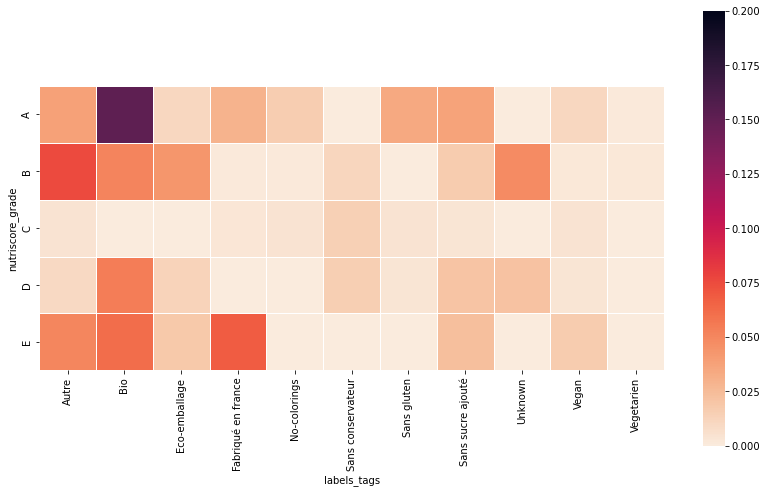

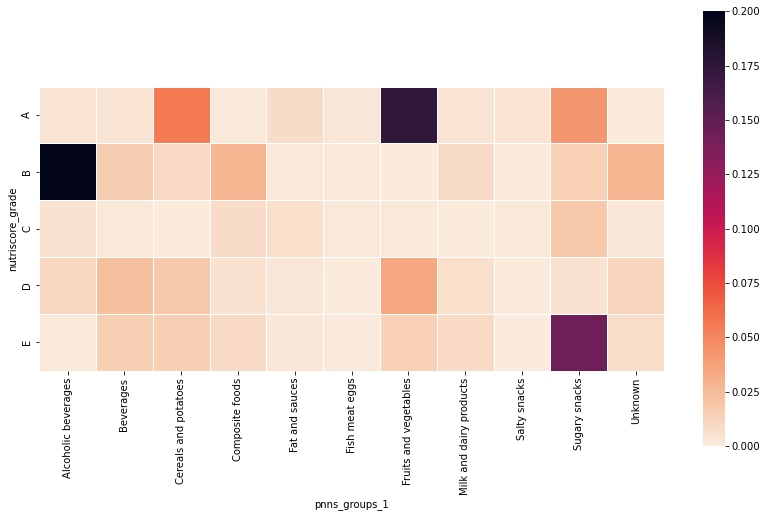

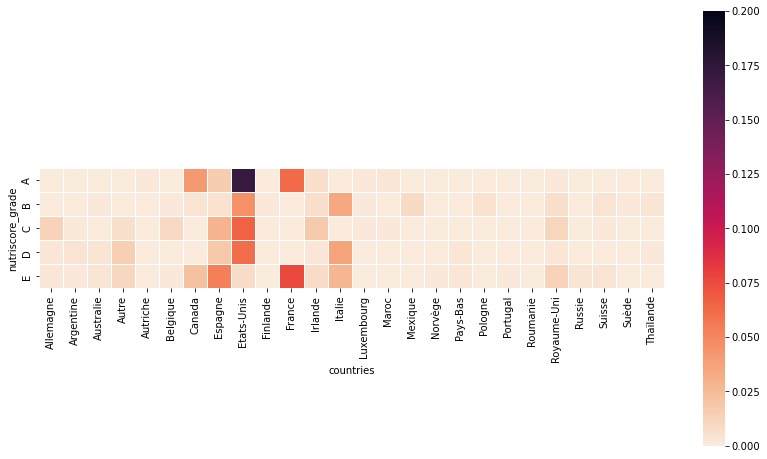

In [54]:
for column in columns_quali_sans_nutri:
    tableau_chi_2_color(df_chi_2, 'nutriscore_grade', column)

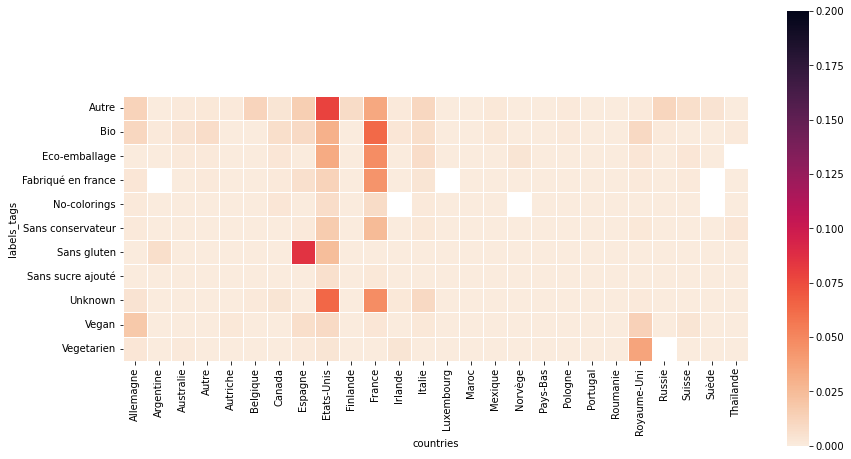

In [55]:
tableau_chi_2_color(df_chi_2, 'labels_tags', 'countries')

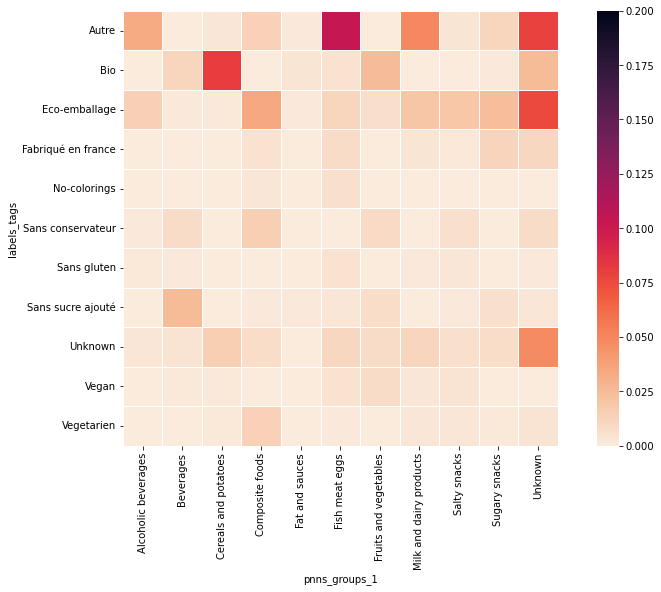

In [56]:
tableau_chi_2_color(df_chi_2, 'labels_tags', 'pnns_groups_1')

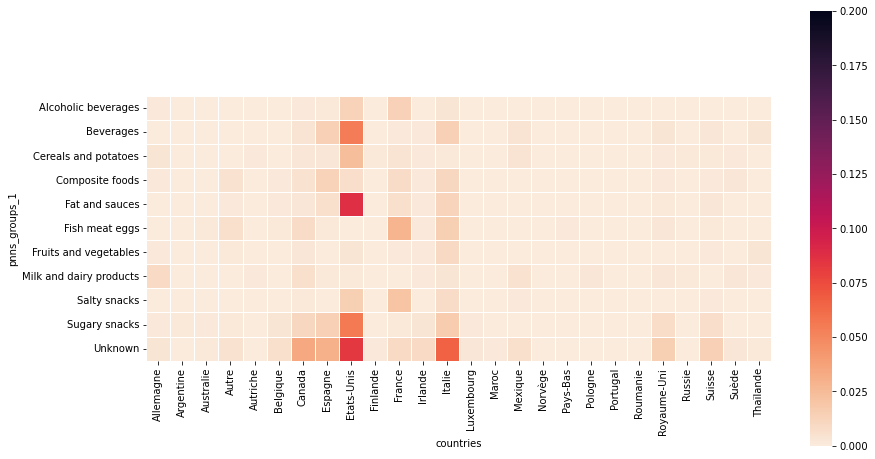

In [57]:
tableau_chi_2_color(df_chi_2, 'pnns_groups_1', 'countries')

Les différentes heatmap corroborent bien la dépendance entre les variables qualitatives (qui était déjà établie avec le test du CHI-2)

# Conclusion

L'étude présentée dans ce notebook a permis de répondre à plusieurs objectifs.

La base de données a été nettoyée pour ne garer que les variables les plus pertinentes. Elle a été débarrassée de ses doublons, des produits impossibles à identifiés et des lignes complètement vides. Les valeurs impossibles des variables quantitatives ont été supprimées. Pour finir, les valeurs manquantes ont ensuite été imputées grâce aux données statistiques des différentes variables.

Les variables ont d’abord été visualisées une part une avec une représentation adéquate quant à leur distribution. Les visualisations interactives ont permis par la suite de présenter de plus en plus de variables sur un même support. De ces représentations sont venus les premières hypothèses de corrélations entre les variables.

Ces hypothèses ont été validées d’abord par la détermination de la corrélation de Pearson entre les variables quantitatives. Il a été validé par exemple que les variables sodium_100g et _salt_100 était fortement corrélées.

L’analyse descriptive par ACP (Analyse en Composantes Principales) a révélé que la base de données pouvait être résumées grâce à 6 axes principaux d’inertie. Malheureusement la projection des produits sur ces axes n’a pas permis de révéler des groupes distinctifs. 

Pour remédier à cela, une méthode de classification par k-means a été réalisé et 6 sous-groupes ont pu être identifiés. Cette fois, la projection des produits sur les composantes principales a montré la distinction entre les groupes.

Enfin, deux analyses explicatives ont révélé la corrélation entre les différentes variables. D’abord le test *ANOVA a montré la corrélation entre les variables quantitatives et les variables qualitatives. Ensuite le test du CHI-2 a montré la dépendance entre les variables qualitatives. La variable nutriscore se trouvant très fortement influencée par les groupes de produits.




Toutes ces analyses pourraient permettre de faire des modèles et des prédictions. Par exemple, il serait possible de déterminer le nutriscore d’un produit grâce à peu de données (et non plus via le calcul effectué par ce notebook). Aussi, il est tout à fait envisageable de déterminer la nature ou la composition d’un produit grâce à quelques paramètres. Enfin, des modèles de consommation pourraient être établis grâce à ces bases de données qui synthétisent les habitudes alimentaires d’une partie des consommateurs.

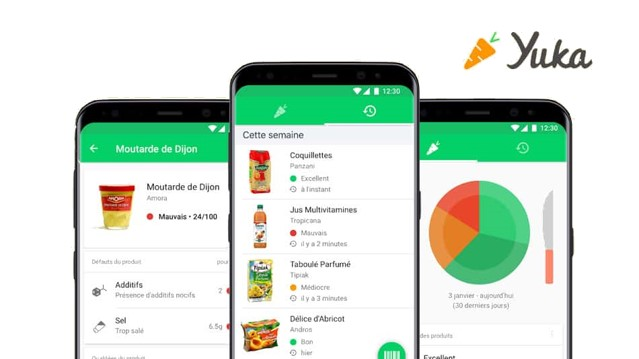

Aujourd’hui de nombreux distributeurs n’affichent pas sur leur produit le Nutriscore associé. Des applications qui s’appuient sur la base de données Open Food Facts, comme Yuka, permettent d’éclairer le consommateur à ce sujet rien qu’en scannant le code bar du produit. Même s’il est encore beaucoup controversé par des fabricants et des consommateurs, le Nutriscore reste une référence pour une majorité de consommateurs avertis.

En matière d'utilité publique, les données issues de cette base de données pour rendre d'innombrables services à la communauté. Outre le Nutriscore, elle permet au consommateur d’élargir la gamme de critères de choix du produit du ajoutant les additifs ou le degré de transformation des aliments (groupe Nova). Une application pourrait tout à fait suggérer une variété de produits au consommateur en fonction de ses critères de consommation. 
En matière de santé, les personnes désireuses de contrôler leur apport en sucres, graisses ou minéraux pourraient paramétrer leur attente sur ces variables et se voir proposer une liste de produits alternatives à leurs choix habituels. Par exemple elle peut proposer une autre marque qui propose le même aliment mais pour un meilleur impact sur la santé ou une meilleure transparence concernant les ingrédients et leur provenance. Aussi elle peut suggérer de diminuer l’achat de produits avec des Nutriscore D et E et de proposer des alternatives.

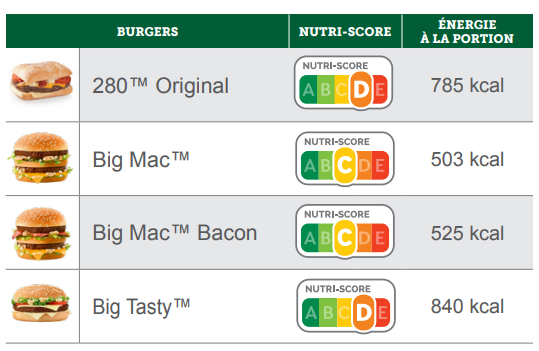

Finalement, l’émergence des applications utilisant une base de données avec autant de variables que celle de cette étude permet à l’utilisateur de passer du statut de simple consommateur à acteur de son propre mode de consommation. 
A noter que le Nutriscore va bientôt être appliqué dans le domaine de la restauration. C’est déjà le car pour les géants de la restauration rapide comme Mc Donald’s La base de données présentée ici pourrait tout à fait être utilisée pour le calcul des Nutriscore des plats. L’efficacité du nettoyage et la robustesse des modèles pour leurs calculs seront un enjeu clé pour être compétitif envers ce nouveau marché des données nutritionnels pour les restaurateurs.